# 18 · Convergence with the sampling of the skewers (TNG50-2, the `points` sweep)


How finely must the points along a skewer be spaced? SkewerJAX's default route on straight skewers needs no sampling:
it deposits every Voronoi cell on its **exact crossing** with the skewer and integrates the line profile over each
crossing. A skewer known only by its points (any path, curved ones included) is cut into the **dual segments** of the
points, the cells crossed found between the midpoints of consecutive points (`pieces="segments"`). This notebook
measures what that costs in accuracy: five spacings $dx$ = 1, 0.5, 0.1, 0.05, 0.01 cMpc, each with the integrated
profile and the exact frame (its $a(s)$ table on the same points), against the fiducial run (the exact crossings,
$a(s)$ every 0.05 cMpc) and against the finest spacing (Parts D and E: against the finest spacing alone). TNG50-2 snapshot 25 ($z = 3$), $128 \times 128$ skewers along $y$,
1 km/s pixels, $\mathrm{Ly}\alpha$ and Si III 1206 (`run_production.py --sweep points`).


Every run is a folder of `scripts/production/run_production.py` (`<OUT>/<SWEEP>/<run>/run.json`) that names its
lattice in the campaign's skewer store; `load_run` reads it. The statistics follow notebooks 11 and 18 on **one line of
sight** ($y$): the transmission $T = e^{-\tau}$ of every line and of the total, its mean $\bar T$, the overflux
$\delta = T/\bar T - 1$, P1D on its native modes and $P(k, \mu)$ of the total in four wedges, and both split
order by order and term by term on the 16 wedges of notebook 11 (`summary_stats.run_statistics`). One line of sight gives no ensemble, so the errors come from a **delete-one-block
jackknife**: the lattice is cut into $4 \times 4$ squares of skewers and each sample leaves one square out (the
3D power of the field with that square set to zero, divided by the fraction kept). Every run is compared with the
reference **bin by bin**, as the relative difference $X_{\rm run}/X_{\rm ref} - 1$, with the jackknife error of that
ratio (`compare_runs`): the runs share the skewer positions and the blocks, so the sample variance they share cancels.
The last part gives, per run, **the largest $k$ up to which every bin differs by less than 0.1%, 0.5% and 1%**
(`k_max_table`; P1D on every native mode, $P(k, \mu)$ on every $|k|$ bin).

Colours: the fiducial run of the campaign in black in every notebook; the other runs from light (coarse) to dark (fine)
on one scale shared by notebooks 18–21.


- **Part A — the stored skewers read back:** every run's lattice, pixels, sampling and dataset, and the checks of the
  pairing (the same positions and pixels in every run).
- **Part B — the statistics of every run** and their comparison with the reference.
- **Part C — the mean transmission.**
- **Part D — P1D by order and by term:** D1 the total and orders 2–4, D2 the order-2 terms (the autos of
  $\mathrm{Ly}\alpha$ and Si III, their cross), every run against the finest spacing, dx = 0.01 cMpc.
- **Part E — $P(k, \mu)$ by order and by term in 16 wedges:** E1 the total and orders 2–4, E2 the order-2 terms,
  one figure each.
- **Part F — the converged range:** the largest $k$ within 0.1%, 0.5% and 1% of the reference, and what it implies.

In [1]:
import os
from pathlib import Path

# ---- configuration: the sweep (scripts/production/run_production.py --sweep points)
SWEEP = "points"
RUNS = ["dx_1cMpc", "dx_0p5cMpc", "dx_0p1cMpc", "dx_0p05cMpc", "dx_0p01cMpc", "reference"]   # coarse to fine, then the fiducial
REFERENCE = "reference"                           # the fiducial run (exact crossings): the converged reference
FINEST = "dx_0p01cMpc"                            # the second reference of Part F
TERMS_REF = FINEST                                # the reference of Parts D and E: the finest spacing (the highest level)
FIDUCIAL = "reference"                            # black in every figure
ORDER = RUNS                                      # the colour scale, coarse to fine
DX = {"dx_1cMpc": 1.0, "dx_0p5cMpc": 0.5, "dx_0p1cMpc": 0.1, "dx_0p05cMpc": 0.05, "dx_0p01cMpc": 0.01}   # [cMpc]
RUN_LABELS = {**{r: f"dx = {x:g} cMpc" for r, x in DX.items()}, "reference": "fiducial (crossings)"}
TITLE_STEM = "Sampling points"
LINTHRESH = 1e-4                                  # [%]: the residual axes are linear within it
OUT = Path(os.environ.get("SKEWERJAX_PRODUCTION", Path.home() / "skewerjax_production"))   # the --out of the campaign
N_SUB = None                                      # None: each run's lattice; 32: a quick check on the nested 32^2 sub-lattice
N_BLOCKS = 4                                      # jackknife: N_BLOCKS x N_BLOCKS squares of skewers
MU_EDGES = (0.0, 0.5, 0.8, 0.95, 1.0)             # the four wedges of P(k, mu) (notebooks 10 and 11's wedges of xi)
TOLS = (0.001, 0.005, 0.01)                       # the convergence levels of Part F
N_MU_TERMS = 16                                   # Parts D and E: the wedges of notebook 11, even in the angle to the line of sight
RES_LINTHRESH = 1e-4                              # [%]: the residual rows of Parts D and E are linear within it
X_OF_RUN, X_LABEL, X_SCALE, X_TICKS = DX, "sampling spacing $dx$ [cMpc]", "log", None

# ---- imports
os.environ.setdefault("JAX_PLATFORMS", "cpu")
import logging; logging.getLogger("jax._src.xla_bridge").setLevel(logging.CRITICAL)
import json, sys, time
import numpy as np
import matplotlib.pyplot as plt
from skewerjax.utils.plotting import use_style, use_backend
# use_backend()                                    # interactive figures in a live notebook
use_style()
from skewerjax.utils.plotting import (TERM_ORDERS, add_panel_letters, field_names, order2_terms, run_styles,
                                      plot_runs_mean_flux, plot_runs_p1d_orders, plot_runs_p1d_terms, plot_runs_pk_mu_orders,
                                      plot_runs_pk_mu_terms, plot_k_max_summary)
from skewerjax.summary_stats import (LatticeWedges, block_labels, compare_runs, format_k_max_table, format_terms_table,
                                     k_max_table, rebin_pixels, run_statistics, set_k_edges)
from skewerjax.utils.reference_data import P1D_DESI_DR1, nearest_reference
from skewerjax.utils.paths import PRODUCTION_DIR, PRODUCTION_SCRIPTS_DIR   # the run folders; the reader of the skewer store
sys.path.insert(0, str(PRODUCTION_SCRIPTS_DIR))
from skewer_store import load_run
from skewerjax.utils.plotting import PALETTE

## Part A — The stored skewers read back

- `OUT`, `SWEEP`, `RUNS`: the run folders `<OUT>/<SWEEP>/<run>` (default `$SKEWERJAX_PRODUCTION`, or
  `~/skewerjax_production`); `REFERENCE` the fiducial run, `FINEST` the finest spacing.
- `N_SUB`: `None` reads each run's $128 \times 128$ lattice; 32 reads its nested $32 \times 32$ sub-lattice (a quick check).
- `N_BLOCKS`, `MU_EDGES`, `TOLS`: the jackknife squares, the wedges, the convergence levels.

The table lists, per run, its lattice, pixels, sampling (in cMpc and in km/s of Hubble flow), route (`streaming`: the
crossings; `sampled`: the dual segments), dataset and cost. The checks: every run has the same skewers (positions) and
the same pixels, so the comparisons are skewer by skewer and pixel by pixel.

In [2]:
RECS = {r: json.loads((OUT / SWEEP / r / "run.json").read_text()) for r in RUNS}
S = {r: load_run(OUT / SWEEP / r, N_SUB) for r in RUNS}          # tau (n_lines, N_sk, N_pix), positions, columns, v, dv, L, u
REF = S[REFERENCE]
L, U, PERIOD = REF.L, REF.u, REF.period                          # [cMpc], aH [km/s per cMpc], v_per [km/s]
N = REF.n_per_axis
Z, A_SNAP = RECS[REFERENCE]["snapshot"]["redshift"], RECS[REFERENCE]["snapshot"]["a"]
LINE_IDS = REF.line_ids
FIELDS = (*LINE_IDS, "total")
NAMES = field_names(FIELDS)
print(f"{'run':<13} {'sim':<8} {'lattice':>8} {'N_pix':>6} {'dv [km/s]':>10} {'dx [cMpc]':>10} {'dx [km/s]':>10} {'route':<10} "
      f"{'dataset':<11} {'computed':>8} {'wall':>8}")
for r in RUNS:
    rec, s, sm = RECS[r], S[r], RECS[r]["sampling"]
    print(f"{r:<13} {s.sim:<8} {s.n_per_axis:>5}^2 {s.v.size:>6} {s.dv:>10.4f} {sm['points_cMpc']:>10.3g} {sm['points_kms']:>10.3g} "
          f"{sm['route']:<10} {rec['dataset']['hash']:<11} {rec['timings']['computed']:>8} {rec['wall_s']:>7.0f}s")
    assert np.isfinite(s.tau).all(), r
for r in RUNS:                                    # tau < 0: the round-off of the engine (float32), relative to each skewer's peak
    t = S[r].tau
    neg = t < 0
    if neg.any():
        worst = (-t.min(axis=-1) / t.max(axis=-1)).max(axis=-1)       # (n_lines,) the largest |tau_min| / tau_max of a skewer
        print(f"{r}: tau < 0 in {neg.mean():.2%} of the samples (" + ", ".join(
              f"{NAMES[l]}: min {t[j].min():.2g}, |min| / max per skewer <= {worst[j]:.1e}" for j, l in enumerate(LINE_IDS) if t[j].min() < 0) + ")")
print(f"\nreference {REFERENCE}: {REF.sim} snapshot {REF.snap}, z = {Z:.4f}, L = {L:.3f} cMpc, u = {U:.3f} km/s per cMpc (1 km/s = {1 / U:.5f} cMpc), "
      f"v_per = {PERIOD:.2f} km/s; tau finite in every run")
print("sampling of the reference: " + RECS[REFERENCE]["sampling"]["effect"])

for r in RUNS:
    assert np.array_equal(S[r].positions, REF.positions) and np.array_equal(S[r].v, REF.v), r
d = {r: np.abs(S[r].tau - REF.tau) for r in RUNS if r != REFERENCE}
print("the same skewers and pixels in every run; |tau_run - tau_ref| per run, median / 99.9th percentile / max over every "
      "line, skewer and pixel:")
for r, x in d.items():
    print(f"  {r:<13} {np.median(x):.2e} / {np.percentile(x, 99.9):.2e} / {x.max():.2e}")
del d

run           sim       lattice  N_pix  dv [km/s]  dx [cMpc]  dx [km/s] route      dataset     computed     wall
dx_1cMpc      TNG50-2    128^2   3949     1.0002          1       76.7 sampled    d5269aff79      6158    5663s
dx_0p5cMpc    TNG50-2    128^2   3949     1.0002        0.5       38.3 sampled    ae7aaa7e4f     16384    6161s
dx_0p1cMpc    TNG50-2    128^2   3949     1.0002        0.1       7.67 sampled    1abe13ee8f     16384    1812s
dx_0p05cMpc   TNG50-2    128^2   3949     1.0002       0.05       3.83 sampled    fe8574d8df     16384    1941s
dx_0p01cMpc   TNG50-2    128^2   3949     1.0002       0.01      0.767 sampled    33dbd3677d     16384    3679s
reference     TNG50-2    128^2   3949     1.0002       0.05       3.83 streaming  e228cdc7b9         0       1s

reference reference: TNG50-2 snapshot 25, z = 3.0081, L = 51.668 cMpc, u = 76.673 km/s per cMpc (1 km/s = 0.01304 cMpc), v_per = 3949.82 km/s; tau finite in every run
sampling of the reference: the a(s) table of th

## Part B — The statistics of every run

The 3D bins are set by the lattice: $|k|$ one bin per mode up to $3.5\,k_f$, steps of $0.4\,k_f$
to 2 cMpc$^{-1}$, then 12 logarithmic bins to the transverse Nyquist frequency $\pi N/L$; the four wedges of
`MU_EDGES` in $\mu = k_\parallel/|k|$. P1D stays on its native modes $k_m = 2\pi m/v_{\rm per}$ for the checks, and is
averaged in 40 logarithmic bins for the figures only. Each line gives the time of each step of a run.

**The decomposition of Parts D and E:** `run_statistics(terms_grid=)` also splits P1D and $P(k, \mu)$ of the total
into its orders and order-2 terms, with the same jackknife, in the 16 wedges of `MU_EDGES_TERMS` on the same $|k|$
bins (`LatticeWedges(store_index=False)`: the transforms along the line of sight first, then across the lattice one
slab of $k_\parallel$ at a time). Two checks are printed per run: the sum of the orders against the total (the sum
rule), and the total against P1D and the four wedges of $P(k, \mu)$ above (the largest difference relative to the
largest value).

In [3]:
KF = 2 * np.pi / L
K_NYQ = np.pi * N / L                                            # the transverse Nyquist frequency of the lattice [1/cMpc]
K_EDGES = set_k_edges(KF, k_1=3.5 * KF, k_2=min(2.0, K_NYQ), k_max=K_NYQ, dk_factor=0.4, n_log=12)
K1D_EDGES = np.geomspace(2 * np.pi / PERIOD, np.pi / min(S[r].dv for r in RUNS), 41)   # display bins of P1D [s/km]
P1D_REF = nearest_reference(P1D_DESI_DR1, Z)
K_DESI = float(np.max(P1D_REF["k"]))                             # [s/km]: the largest k of DESI DR1 at the snapshot's z
MU_EDGES_TERMS = np.sin(np.linspace(0.0, np.pi / 2, N_MU_TERMS + 1))   # the wedges of Parts D and E
GRIDS = {}


def grid_for(n, n_pix):
    """The mu wedges of P on an n x n lattice of n_pix pixels (LatticeWedges: the bins of lattice_grid's P_mu alone, the memory of
    512^2 lattices), cached: the same |k| edges and mu wedges for every run."""
    if (n, n_pix) not in GRIDS:
        GRIDS[n, n_pix] = LatticeWedges(n, n_pix, L, k_edges=K_EDGES, mu_edges=MU_EDGES)
    return GRIDS[n, n_pix]


def terms_grid_for(n, n_pix):
    """The 16 wedges of the decomposition (Parts D and E), without an index (streamed by run_statistics)."""
    if (n, n_pix, "terms") not in GRIDS:
        GRIDS[n, n_pix, "terms"] = LatticeWedges(n, n_pix, L, k_edges=K_EDGES, mu_edges=MU_EDGES_TERMS, store_index=False)
    return GRIDS[n, n_pix, "terms"]


def statistics(s, transmissions=None, n_pix=None, dv=None, decompose=True):
    """run_statistics of one run (or of ``transmissions`` on ``n_pix`` pixels of ``dv``) on its lattice's jackknife blocks
    and bins, T_bar the mean over every pixel (one scale factor: the box), with the time of each step; with its
    decomposition by order and term on the 16 wedges (decompose=False: the total alone)."""
    n_pix = s.v.size if n_pix is None else n_pix
    steps = []
    out = run_statistics(None if transmissions is not None else s.tau, s.dv if dv is None else dv, line_ids=LINE_IDS,
                         labels=block_labels(s.columns, s.n_per_axis, N_BLOCKS), grid=grid_for(s.n_per_axis, n_pix),
                         transmissions=transmissions, a_pix=np.full(n_pix, A_SNAP), log=steps.append,
                         terms_grid=terms_grid_for(s.n_per_axis, n_pix), decompose=decompose)
    return out, steps


STATS, T0 = {}, time.perf_counter()
for r in RUNS:
    t = time.perf_counter()
    STATS[r], steps = statistics(S[r])
    print(f"{r:<13} {time.perf_counter() - t:6.1f} s: " + "; ".join(steps))
    tr = STATS[r]["terms"]
    print(f"{'':<13} sum of the orders vs the total: P1D {tr['sum_rule']['p1d']:.1e}, P(k, mu) {tr['sum_rule']['P_mu']:.1e}; "
          f"the total vs P1D and the 4 wedges above: {tr['check']['p1d']:.1e}, {tr['check']['P_mu']:.1e}")
CMP = {r: compare_runs(STATS[r], STATS[REFERENCE], k_edges_1d=K1D_EDGES) for r in RUNS if r != REFERENCE}   # display bins
CMP_ALL = {r: compare_runs(STATS[r], STATS[REFERENCE]) for r in RUNS if r != REFERENCE}                  # every mode: the checks
STYLES = run_styles(ORDER, fiducial=FIDUCIAL)
print(f"every run in {time.perf_counter() - T0:.0f} s; P(k, mu) in {len(MU_EDGES) - 1} wedges x {len(K_EDGES) - 1} |k| bins up to "
      f"{K_NYQ:.2f} cMpc^-1; jackknife over {N_BLOCKS} x {N_BLOCKS} squares of {N // N_BLOCKS} x {N // N_BLOCKS} skewers")

CMP_T = {r: compare_runs(STATS[r], STATS[TERMS_REF], k_edges_1d=K1D_EDGES) for r in RUNS if r != TERMS_REF}   # Parts D, E
CMP_FINEST_ALL = {r: compare_runs(STATS[r], STATS[FINEST]) for r in RUNS if r not in (FINEST, REFERENCE)}
TERMS = order2_terms(CMP_T)                                      # the order-2 terms of D2 and E2: the autos, the cross
K_LIMITS_T = (2 * np.pi / PERIOD, np.pi / min(S[r].dv for r in CMP_T))   # [s/km]: the P1D range the runs share with TERMS_REF


dx_1cMpc        55.9 s: transmissions of 16,384 skewers x 3949 pixels (1.5 s); P1D of HI-LyA (1.8 s); P1D of SiIII-1206 (1.7 s); P1D of total (1.7 s); P(k, mu) of total and its 16 jackknife samples (10.3 s); the transforms along the line of sight and P1D of 11 pairs (21.2 s); P(k, mu) of 11 pairs and their 16 jackknife samples in slabs of 32 k_par (14.7 s)
              sum of the orders vs the total: P1D 1.7e-09, P(k, mu) 2.4e-07; the total vs P1D and the 4 wedges above: 7.1e-16, 6.9e-08
dx_0p5cMpc      57.2 s: transmissions of 16,384 skewers x 3949 pixels (1.7 s); P1D of HI-LyA (1.5 s); P1D of SiIII-1206 (1.4 s); P1D of total (1.4 s); P(k, mu) of total and its 16 jackknife samples (8.1 s); the transforms along the line of sight and P1D of 11 pairs (23.0 s); P(k, mu) of 11 pairs and their 16 jackknife samples in slabs of 32 k_par (20.0 s)
              sum of the orders vs the total: P1D 1.7e-09, P(k, mu) 5.0e-08; the total vs P1D and the 4 wedges above: 5.3e-16, 4.3e-08
dx_0p1cMpc   

## Part C — The mean transmission

$\bar F$ of every line and of the total, per run, as $100\,(\bar F_{\rm run}/\bar F_{\rm ref} - 1)$ [%] with its
jackknife error (the reference is the line at 0; the grey band is $\pm 0.5\%$, the dotted lines $\pm 0.1\%$ and
$\pm 1\%$; the axis is linear within `LINTHRESH`).

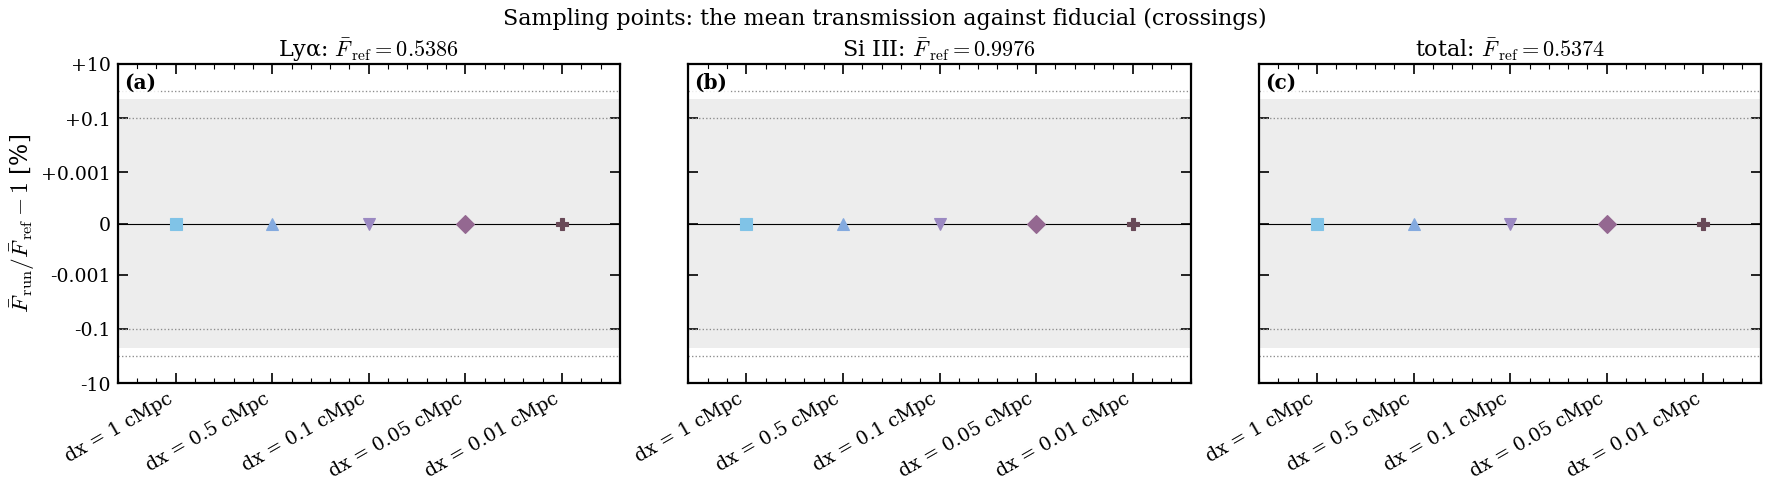

dx_1cMpc      Lyα: -3.24e-06 +- 2.7e-07 %; Si III: -3.17e-08 +- 7.1e-09 %; total: -3.27e-06 +- 2.7e-07 %
dx_0p5cMpc    Lyα: -3.09e-06 +- 1.9e-07 %; Si III: -3.22e-08 +- 7.4e-09 %; total: -3.12e-06 +- 1.9e-07 %
dx_0p1cMpc    Lyα: -2.97e-06 +- 2.6e-07 %; Si III: -2.94e-08 +- 8.3e-09 %; total: -3e-06 +- 2.6e-07 %
dx_0p05cMpc   Lyα: -2.69e-06 +- 2.2e-07 %; Si III: -3.29e-08 +- 6.9e-09 %; total: -2.73e-06 +- 2.2e-07 %
dx_0p01cMpc   Lyα: -2.34e-06 +- 2.3e-07 %; Si III: -3.58e-08 +- 8.2e-09 %; total: -2.37e-06 +- 2.3e-07 %


In [4]:
fig, axs = plot_runs_mean_flux(CMP, STYLES, REFERENCE, field_labels=NAMES, labels=RUN_LABELS, linthresh=LINTHRESH,
                               title=f"{TITLE_STEM}: the mean transmission against {RUN_LABELS[REFERENCE]}")
add_panel_letters(axs)
plt.show()
for r, c in CMP_ALL.items():
    print(f"{r:<13} " + "; ".join(f"{NAMES[f]}: {100 * c['mean_flux']['rel'][j]:+.3g} +- {100 * c['mean_flux']['err'][j]:.2g} %"
                                  for j, f in enumerate(FIELDS)))

## Part D — P1D by order and by term

**The orders and the terms** (notebook 11, Parts E and F; `docs/decomposition.md`). With $\delta_j = T_j/\bar T_j - 1$
the overflux of line $j$ and $\mathcal C = \bar T/\prod_j \bar T_j - 1$, the total overflux is exactly a sum of subset
fields, $\delta_{\rm tot} = \sum_A F_A$, with $F_\emptyset = -\mathcal C/(1+\mathcal C)$ and
$F_A = \prod_{j\in A}\delta_j/(1+\mathcal C)$. Every two-point statistic of the total is then the sum of the
cross-statistics of the pairs $(A, B)$, grouped by the order $n = |A| + |B| = 0, \dots, 4$ for two lines:

* **order 2:** the $\mathrm{Ly}\alpha$ auto ($F_{\rm Ly\alpha}$ with itself), the Si III auto, their cross
  ($2\,\mathrm{Re}\,P_{\rm Ly\alpha, Si\,III}$, which oscillates as $\cos(k_\parallel \Delta v)$ with the separation
  $\Delta v$ of the lines) and a $\mathcal C$ term;
* **order 3:** each line with the product of the two; **order 4:** the product with itself.

**Orders 0 and 1 are not shown.** They hold only the $\mathcal C$ terms, the corrections of the mean, which vanish on
average. In one snapshot $\mathcal C$ is a single number (`MEAN = "redshift"` with one $a$), so $F_\emptyset$ is a
constant whose power lives at $k = 0$ alone, which P1D at $k > 0$ and $P(k, \mu)$ leave out; the $\mathcal C$ term of
order 2 vanishes alike. At every $k > 0$: total = order 2 + order 3 + order 4 (the sum rule printed in Part B).

**The figures.** Every run against **the finest spacing, dx = 0.01 cMpc** (the highest level of the sweep), drawn thick and light underneath with
its jackknife error as a faint band. Above, $kP_{\rm 1D}/\pi$ in 40 logarithmic display bins. Below, the difference
$\Delta = X_{\rm run} - X_{\rm ref}$ in per cent of $|X_{\rm ref}|$, on the grey band of the reference's jackknife error:
a residual inside the band is not significant. The residual axis is symmetric-log, linear within `RES_LINTHRESH`. A
quantity that changes sign (the cross term, order 3) has a symmetric-log main axis, and where $|X_{\rm ref}|$ falls
below 1% of its maximum in the panel, $\Delta$ is divided by the local envelope of $|X_{\rm ref}|$ instead (its running
maximum over $\pm 2$ bins; open markers). The grey bands lie outside $[2\pi/v_{\rm per}, \pi/dv]$; the dashed line is the
largest $k$ of DESI DR1 at the snapshot's redshift. The tables list, per run and quantity for $k \le k_{\rm DESI}$, the median and largest $|\Delta|$, the median error of the reference, and the share of bins
outside it.

### D1 · P1D by order

The total and orders 2, 3, 4.

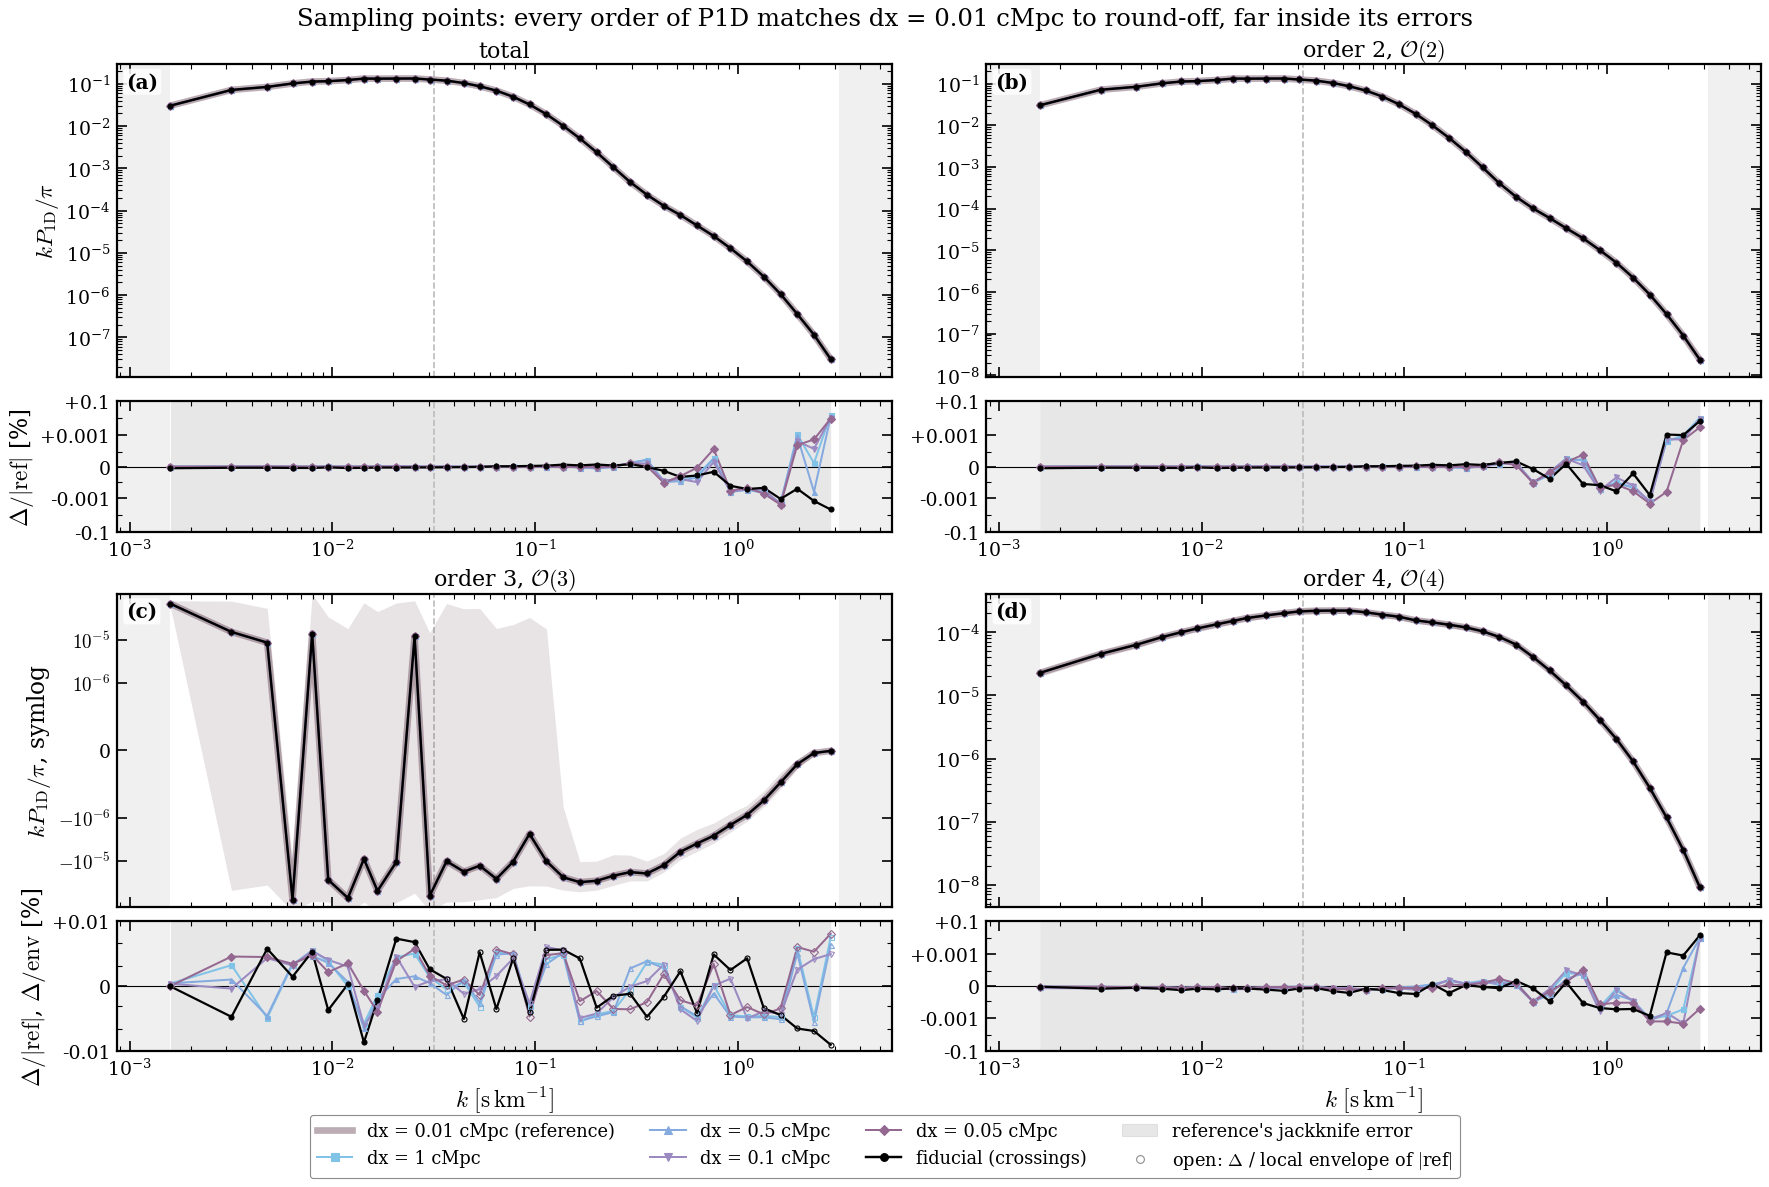

k <= 0.032 s/km, against dx_0p01cMpc:
run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dx_1cMpc       total                              1.16e-06     1.97e-06        2.81       0%
dx_1cMpc       order 2                            1.17e-06        2e-06        2.82       0%
dx_1cMpc       order 3                            0.000138     0.000598         319       0%
dx_1cMpc       order 4                            9.16e-06      1.7e-05        11.3       0%
dx_0p5cMpc     total                              8.96e-07     1.61e-06        2.81       0%
dx_0p5cMpc     order 2                            8.93e-07     1.65e-06        2.82       0%
dx_0p5cMpc     order 3                            5.67e-05     0.000961         319       0%
dx_0p5cMpc     order 4                            6.32e-06     1.44e-05        11.3       0%
dx_0p1cMpc     total                              7.06e-07     1.48e-06        2.81       0%
dx_0p1cMpc     order 2          

In [5]:
fig, main, res = plot_runs_p1d_orders(CMP_T, STYLES, TERMS_REF, line_ids=LINE_IDS, labels=RUN_LABELS, linthresh=RES_LINTHRESH,
                                      k_limits=K_LIMITS_T, k_mark=K_DESI,
                                      title='Sampling points: every order of P1D matches dx = 0.01 cMpc to round-off, far inside its errors')
add_panel_letters(main)
plt.show()
print(f"k <= {K_DESI:.3f} s/km, against {TERMS_REF}:")
print(format_terms_table(CMP_T, TERM_ORDERS, "p1d", k_max=K_DESI))

*Reading.* Look for any residual leaving the band: none does. In the DESI range the total and
orders 2 and 4 differ from dx = 0.01 cMpc by a median $\sim 10^{-6}$% (at most $3\times10^{-5}$%); order 3 (it changes sign,
open markers) by $\sim 10^{-4}$% of its envelope. The errors of the reference are 3% (total), 11% (order 4) and more for
order 3: the spacing changes nothing. The fiducial (the exact crossings, black) is the farthest from dx = 0.01 cMpc, at
$\sim 10^{-5}$%: two routes, the same result to float32 round-off.

### D2 · P1D term by term (order 2)

The $\mathrm{Ly}\alpha$ auto, the Si III auto and their cross term.

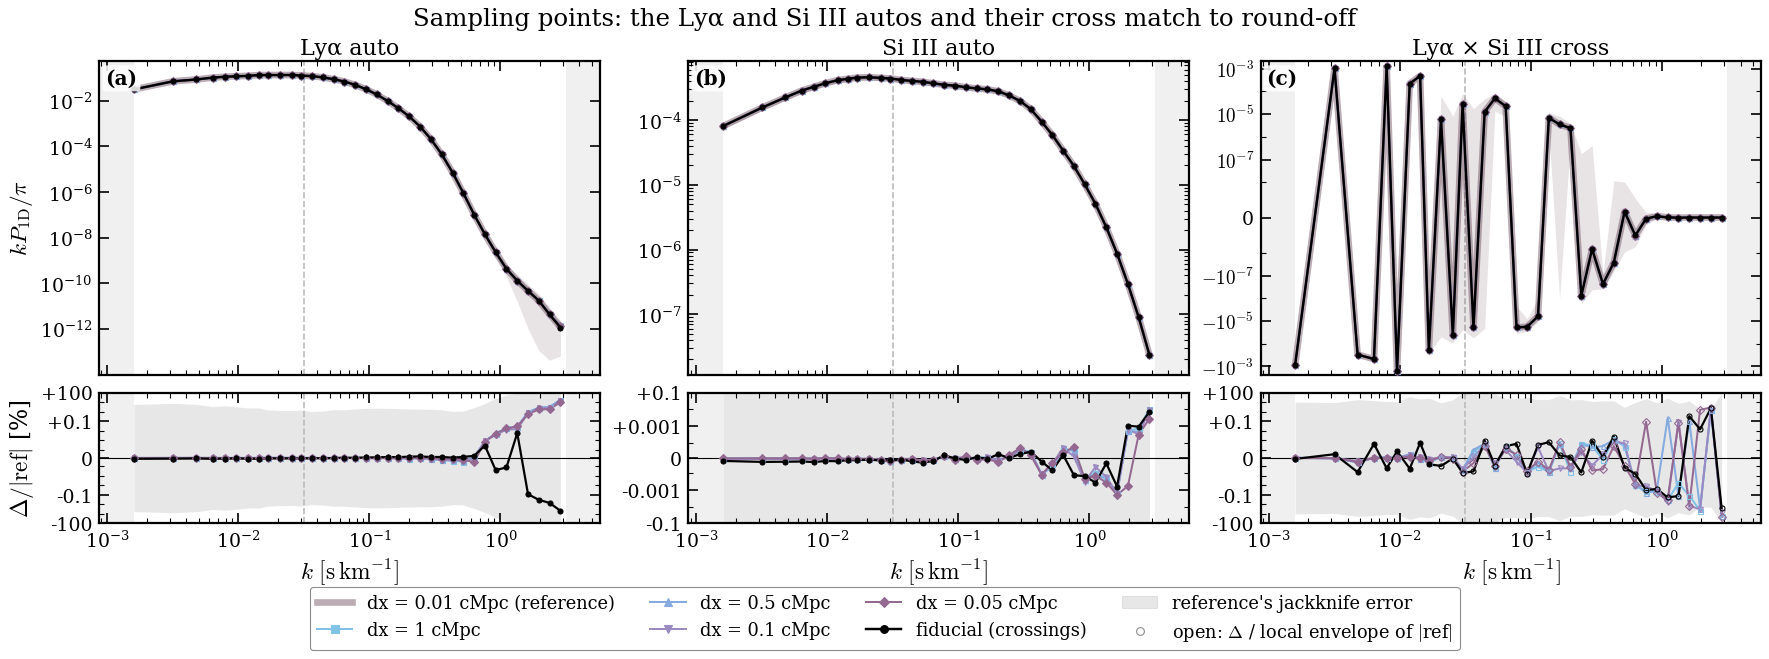

k <= 0.032 s/km, against dx_0p01cMpc:
run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dx_1cMpc       HI-LyA|HI-LyA                      1.18e-06      2.1e-06        2.81       0%
dx_1cMpc       SiIII-1206|SiIII-1206              4.61e-06     1.78e-05        9.26       0%
dx_1cMpc       HI-LyA|SiIII-1206                  9.45e-06     0.000217        15.7       0%
dx_0p5cMpc     HI-LyA|HI-LyA                      9.54e-07     1.76e-06        2.81       0%
dx_0p5cMpc     SiIII-1206|SiIII-1206              3.47e-06     1.47e-05        9.26       0%
dx_0p5cMpc     HI-LyA|SiIII-1206                  7.95e-06     0.000237        15.7       0%
dx_0p1cMpc     HI-LyA|HI-LyA                      6.96e-07      1.6e-06        2.81       0%
dx_0p1cMpc     SiIII-1206|SiIII-1206              7.97e-06     1.62e-05        9.26       0%
dx_0p1cMpc     HI-LyA|SiIII-1206                  8.05e-06     0.000196        15.7       0%
dx_0p05cMpc    HI-LyA|HI-LyA    

In [6]:
fig, main, res = plot_runs_p1d_terms(CMP_T, STYLES, TERMS_REF, terms=TERMS, line_ids=LINE_IDS, labels=RUN_LABELS,
                                     linthresh=RES_LINTHRESH, k_limits=K_LIMITS_T,
                                     k_mark=K_DESI, title="Sampling points: the Lyα and Si III autos and their cross match to round-off")
add_panel_letters(main)
plt.show()
print(f"k <= {K_DESI:.3f} s/km, against {TERMS_REF}:")
print(format_terms_table(CMP_T, TERMS, "p1d", k_max=K_DESI))

*Reading.* Every term agrees with dx = 0.01 cMpc to $10^{-6}$–$10^{-4}$% in the DESI range. The one
visible departure is the $\mathrm{Ly}\alpha$ auto above $k \approx 1$ s/km (up to 17%), where its $kP/\pi$ is
$10^{-12}$ and below: the float32 round-off of saturated absorbers (Part F). The total does not see it, because above
$\sim 1$ s/km its P1D is the Si III auto (panel b lies five decades above panel a there).

## Part E — The wedges of $P(k, \mu)$ by order and by term

The 3D counterpart of Part D: $P(k, \mu)$ of the total overflux, of its orders and of its order-2 terms in the 16 wedges
of notebook 11 (`MU_EDGES_TERMS`, evenly spaced in the angle to the line of sight; Part F keeps the four wedges of
`MU_EDGES`), on the $|k|$ bins of Part B. Each quantity has one figure, with the wedges in the grid of notebook 11 (F1)
and a residual row under each wedge, as in Part D. A cell without modes is not drawn. The tables list, per run and
quantity over every wedge and bin, the same numbers as in Part D.

### E1 · The wedges by order

One figure each for the total and orders 2, 3, 4.

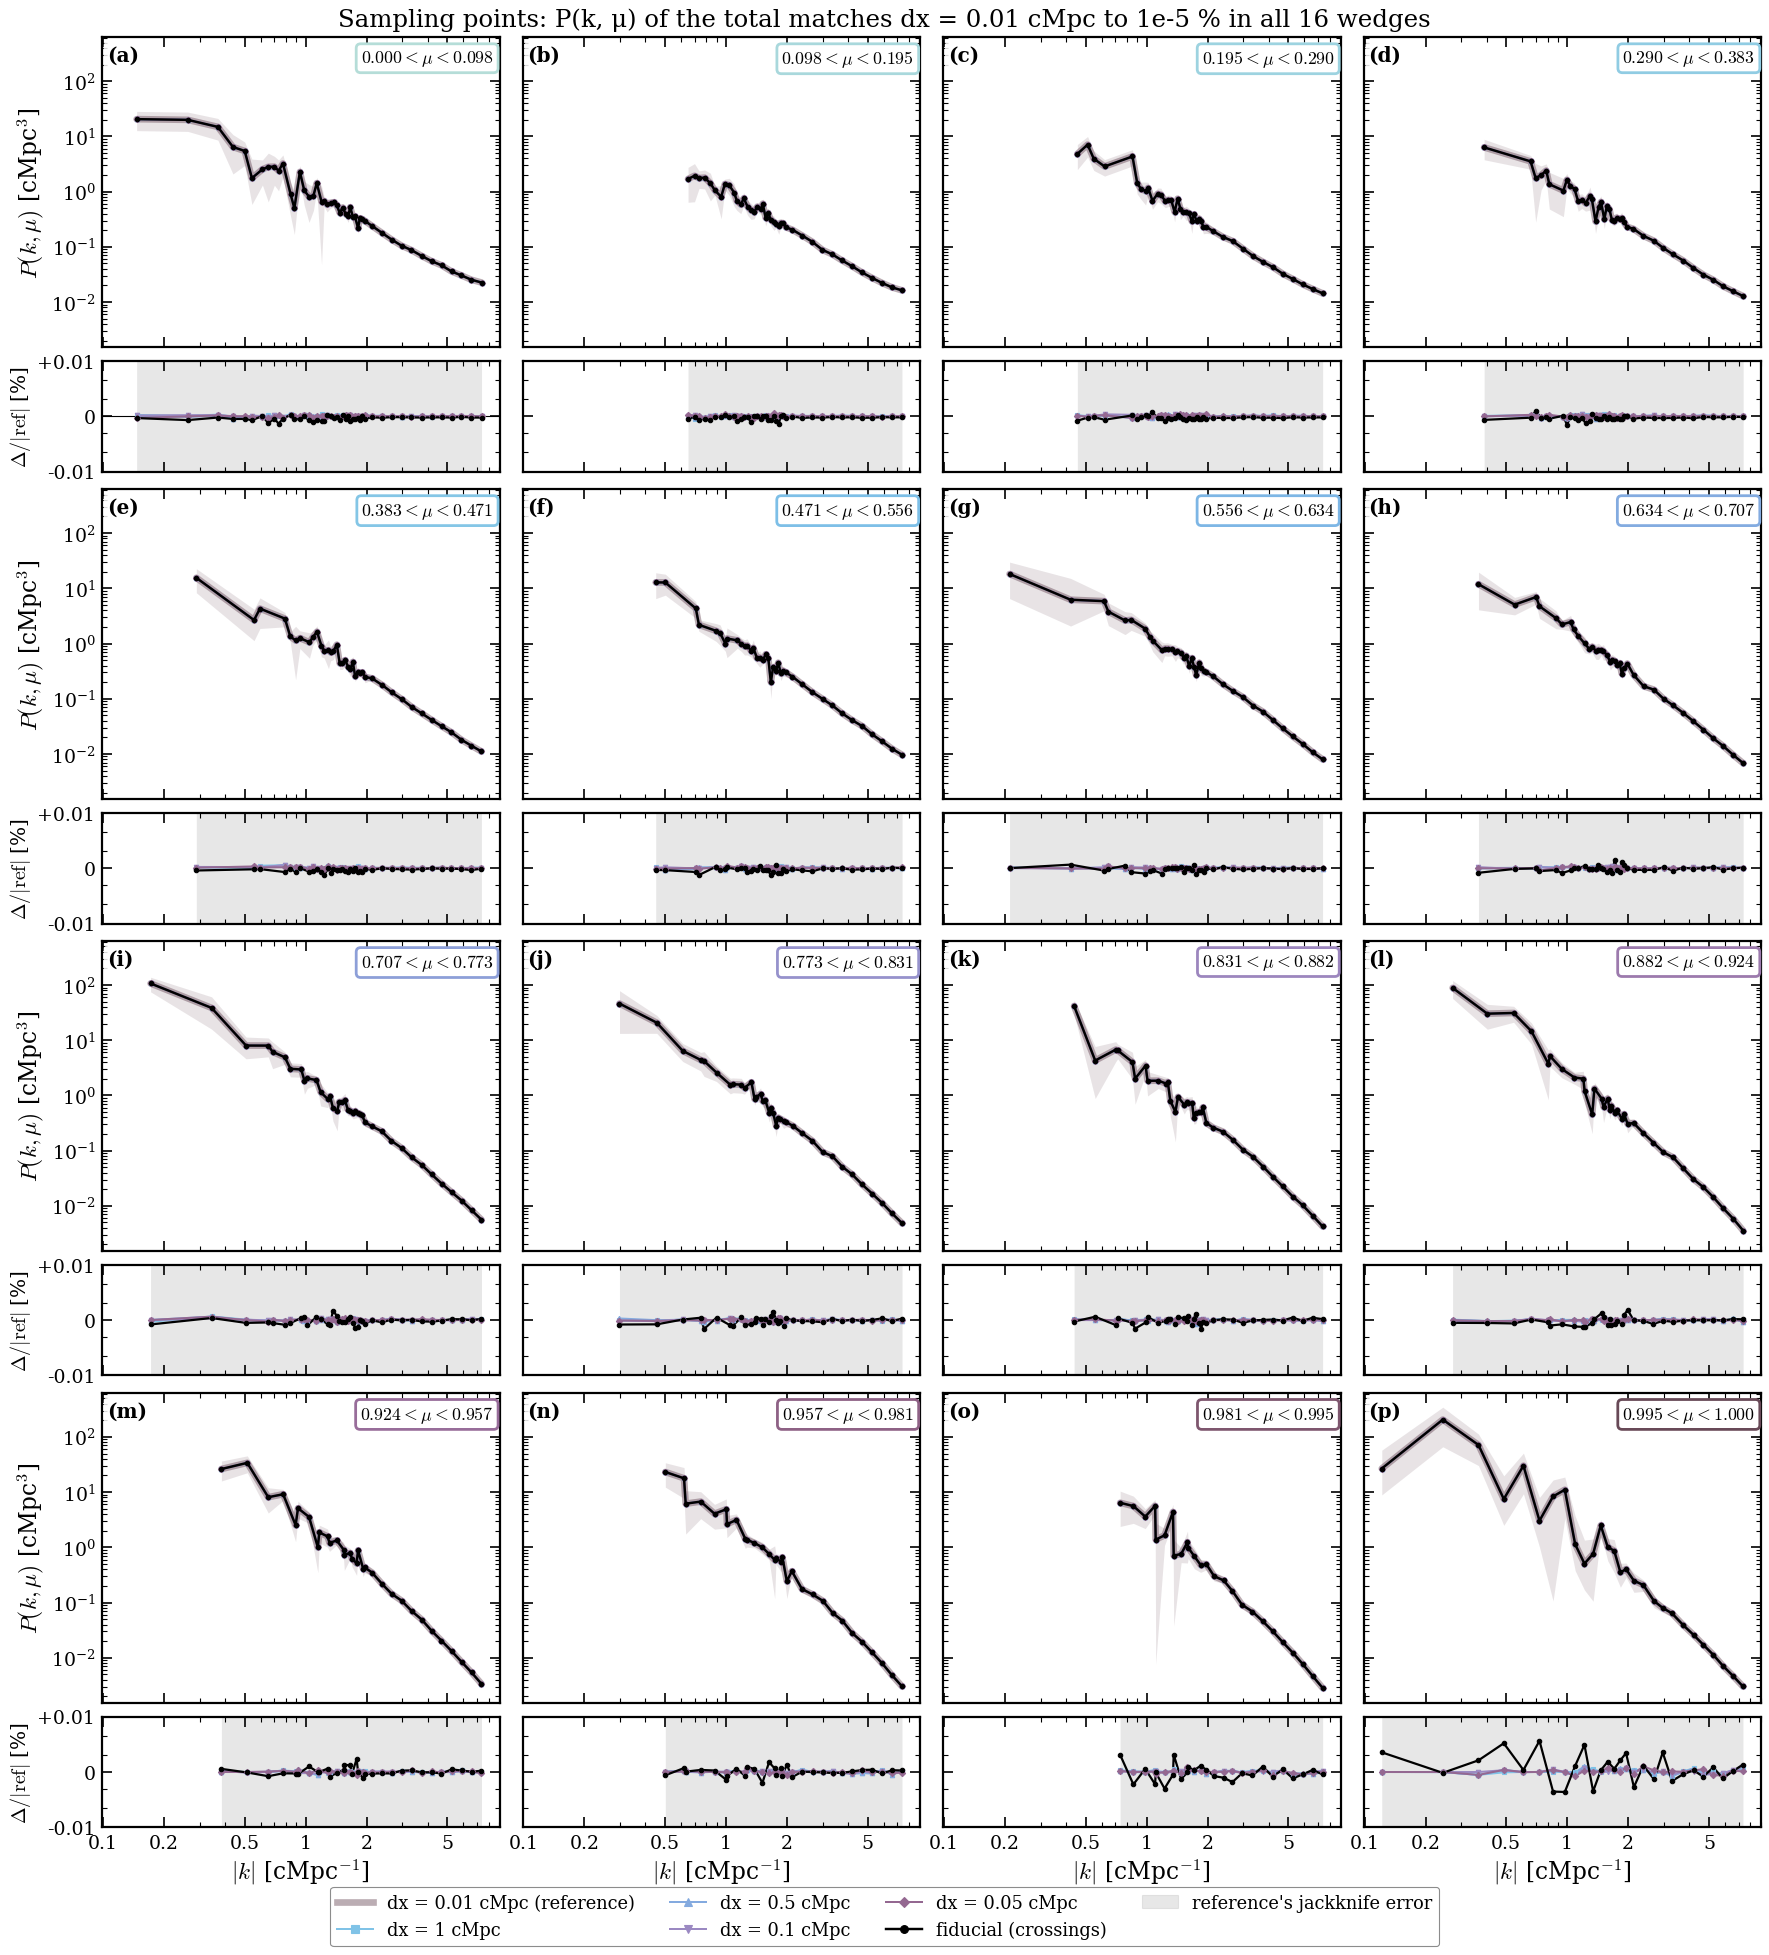

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dx_1cMpc       total                              3.07e-06     2.66e-05        21.9       0%
dx_0p5cMpc     total                              3.07e-06     3.54e-05        21.9       0%
dx_0p1cMpc     total                              2.81e-06     2.68e-05        21.9       0%
dx_0p05cMpc    total                              2.74e-06      3.3e-05        21.9       0%
reference      total                              1.06e-05     0.000549        21.9       0%


In [7]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('total',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'total': "Sampling points: P(k, μ) of the total matches dx = 0.01 cMpc to 1e-5 % in all 16 wedges"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('total',), "P_mu"))

*Reading (total).* Median $|\Delta| = 3\times10^{-6}$% (at most $5\times10^{-4}$%, the fiducial) in every
wedge and bin, against a reference error of $\sim 20$%. No wedge, near the line of sight or across it, reacts.

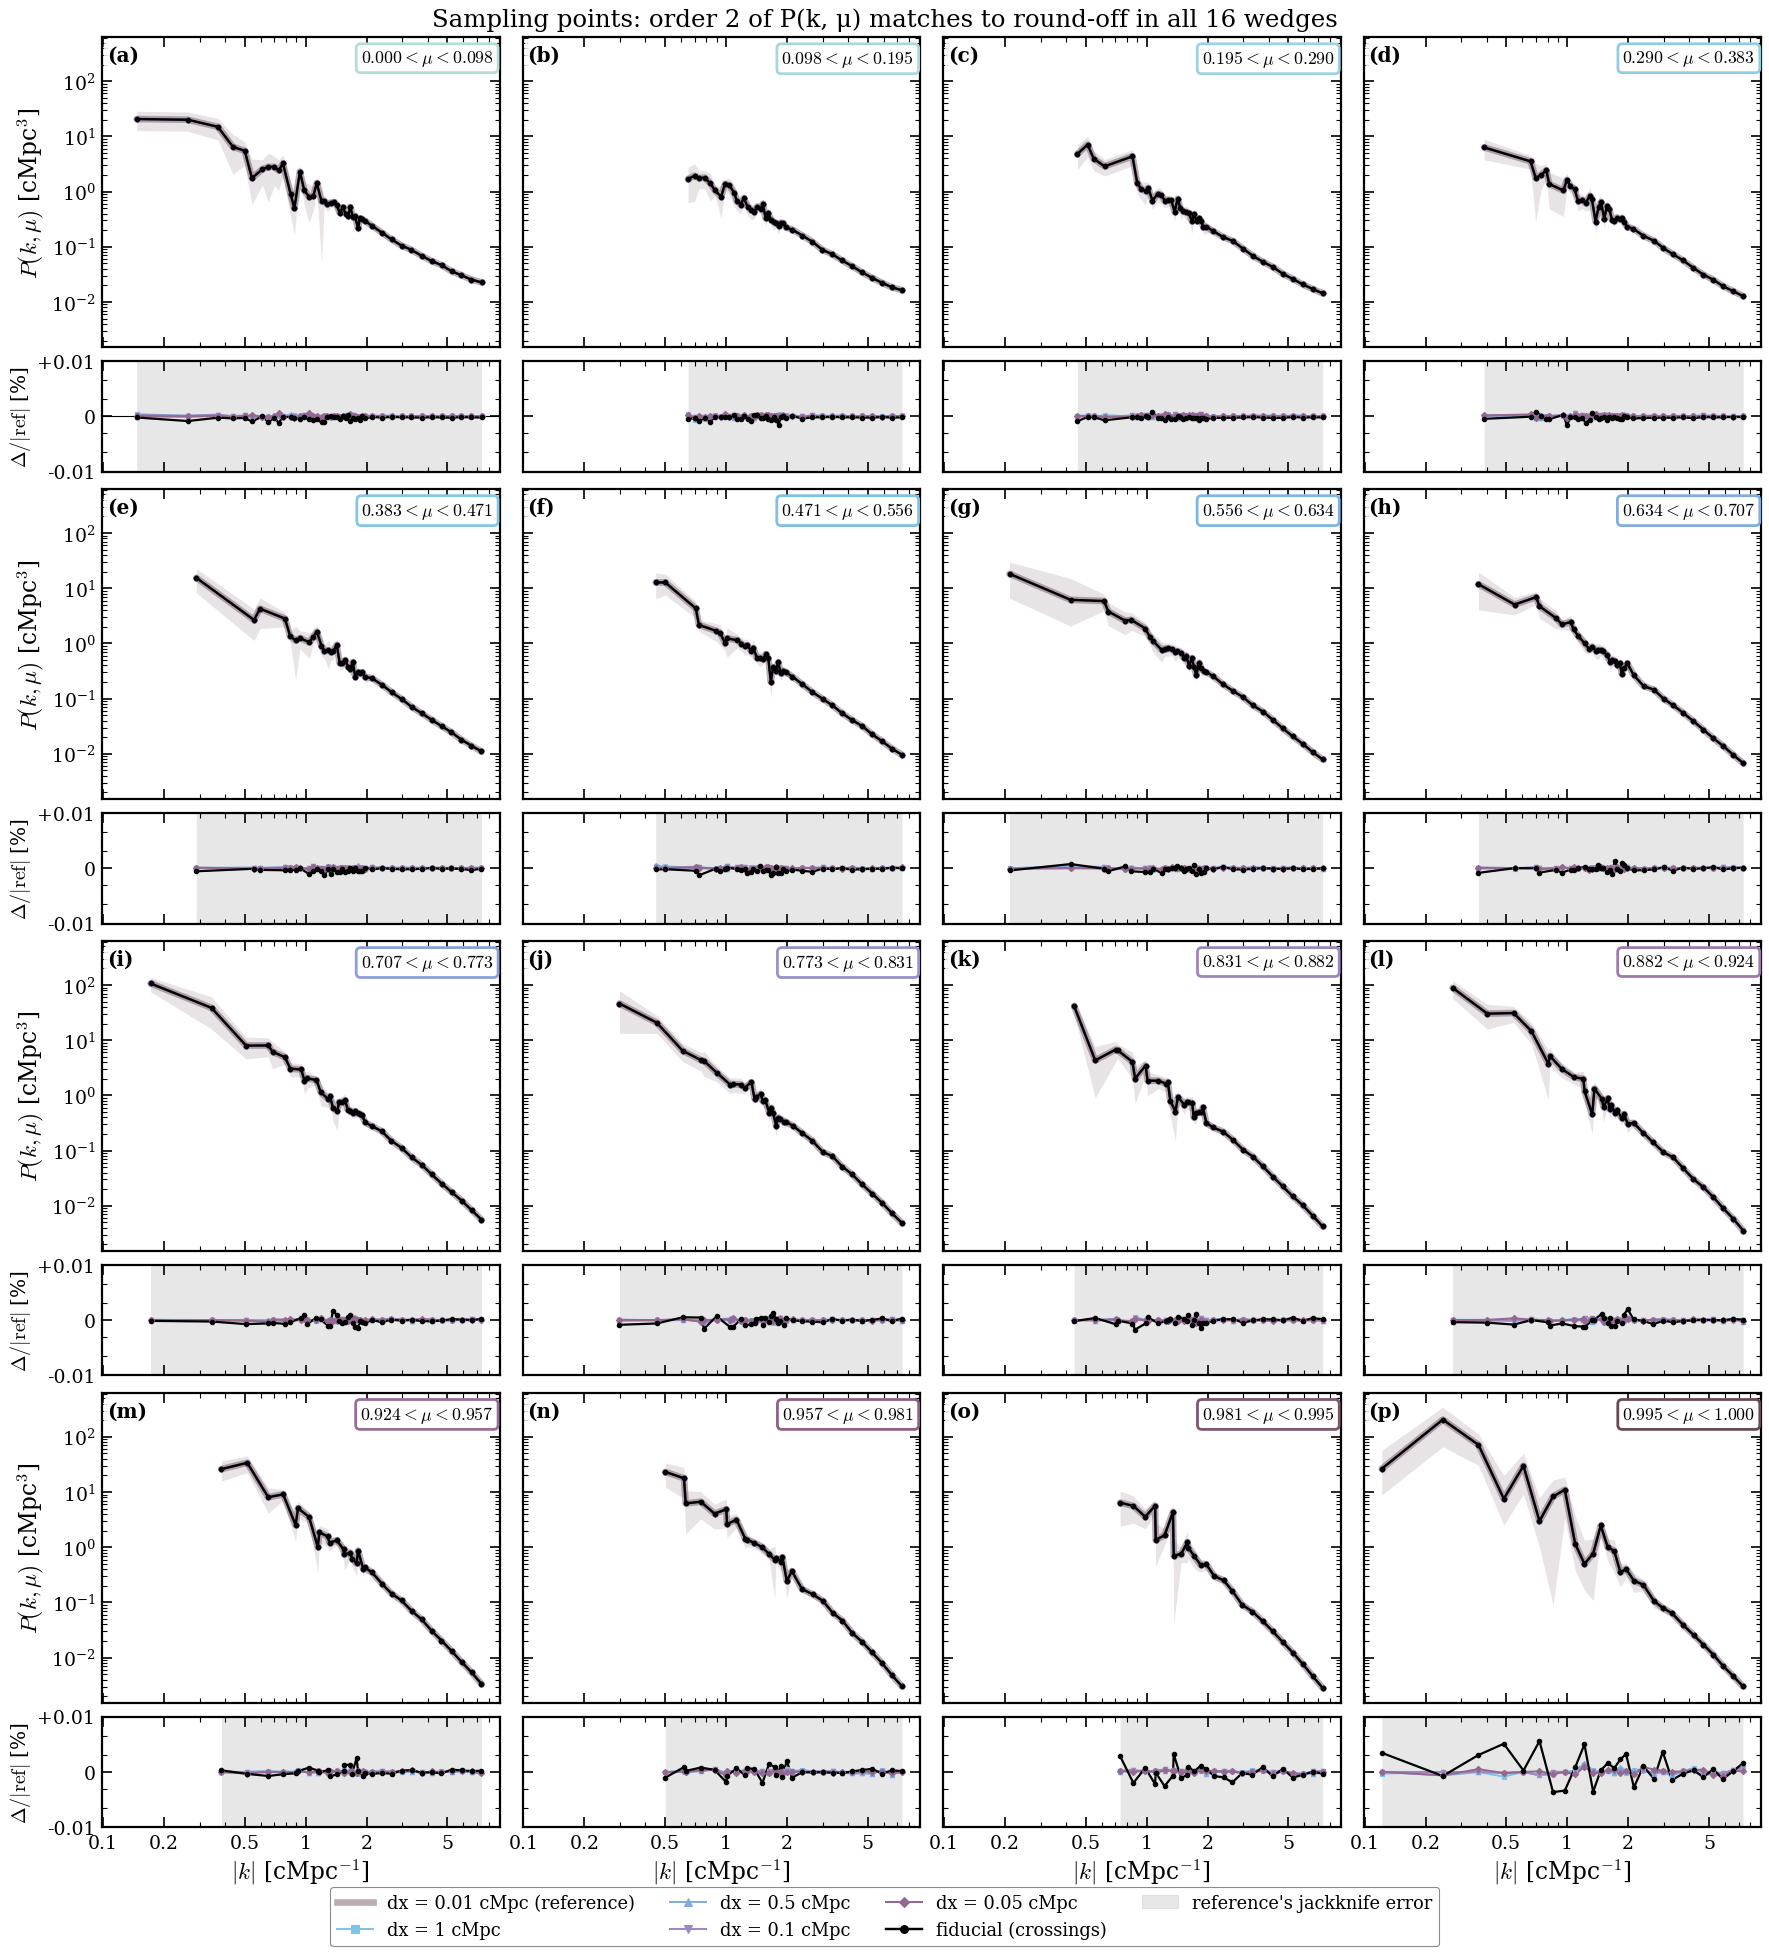

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dx_1cMpc       order 2                            3.09e-06     4.21e-05          22       0%
dx_0p5cMpc     order 2                            2.99e-06     5.15e-05          22       0%
dx_0p1cMpc     order 2                             2.8e-06     4.24e-05          22       0%
dx_0p05cMpc    order 2                            2.73e-06     3.11e-05          22       0%
reference      order 2                            9.92e-06     0.000528          22       0%


In [8]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('order 2',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'order 2': "Sampling points: order 2 of P(k, μ) matches to round-off in all 16 wedges"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('order 2',), "P_mu"))

*Reading (order 2).* Order 2 is the total up to $3\times10^{-4}$ (notebook 11): the same agreement, median
$3\times10^{-6}$%.

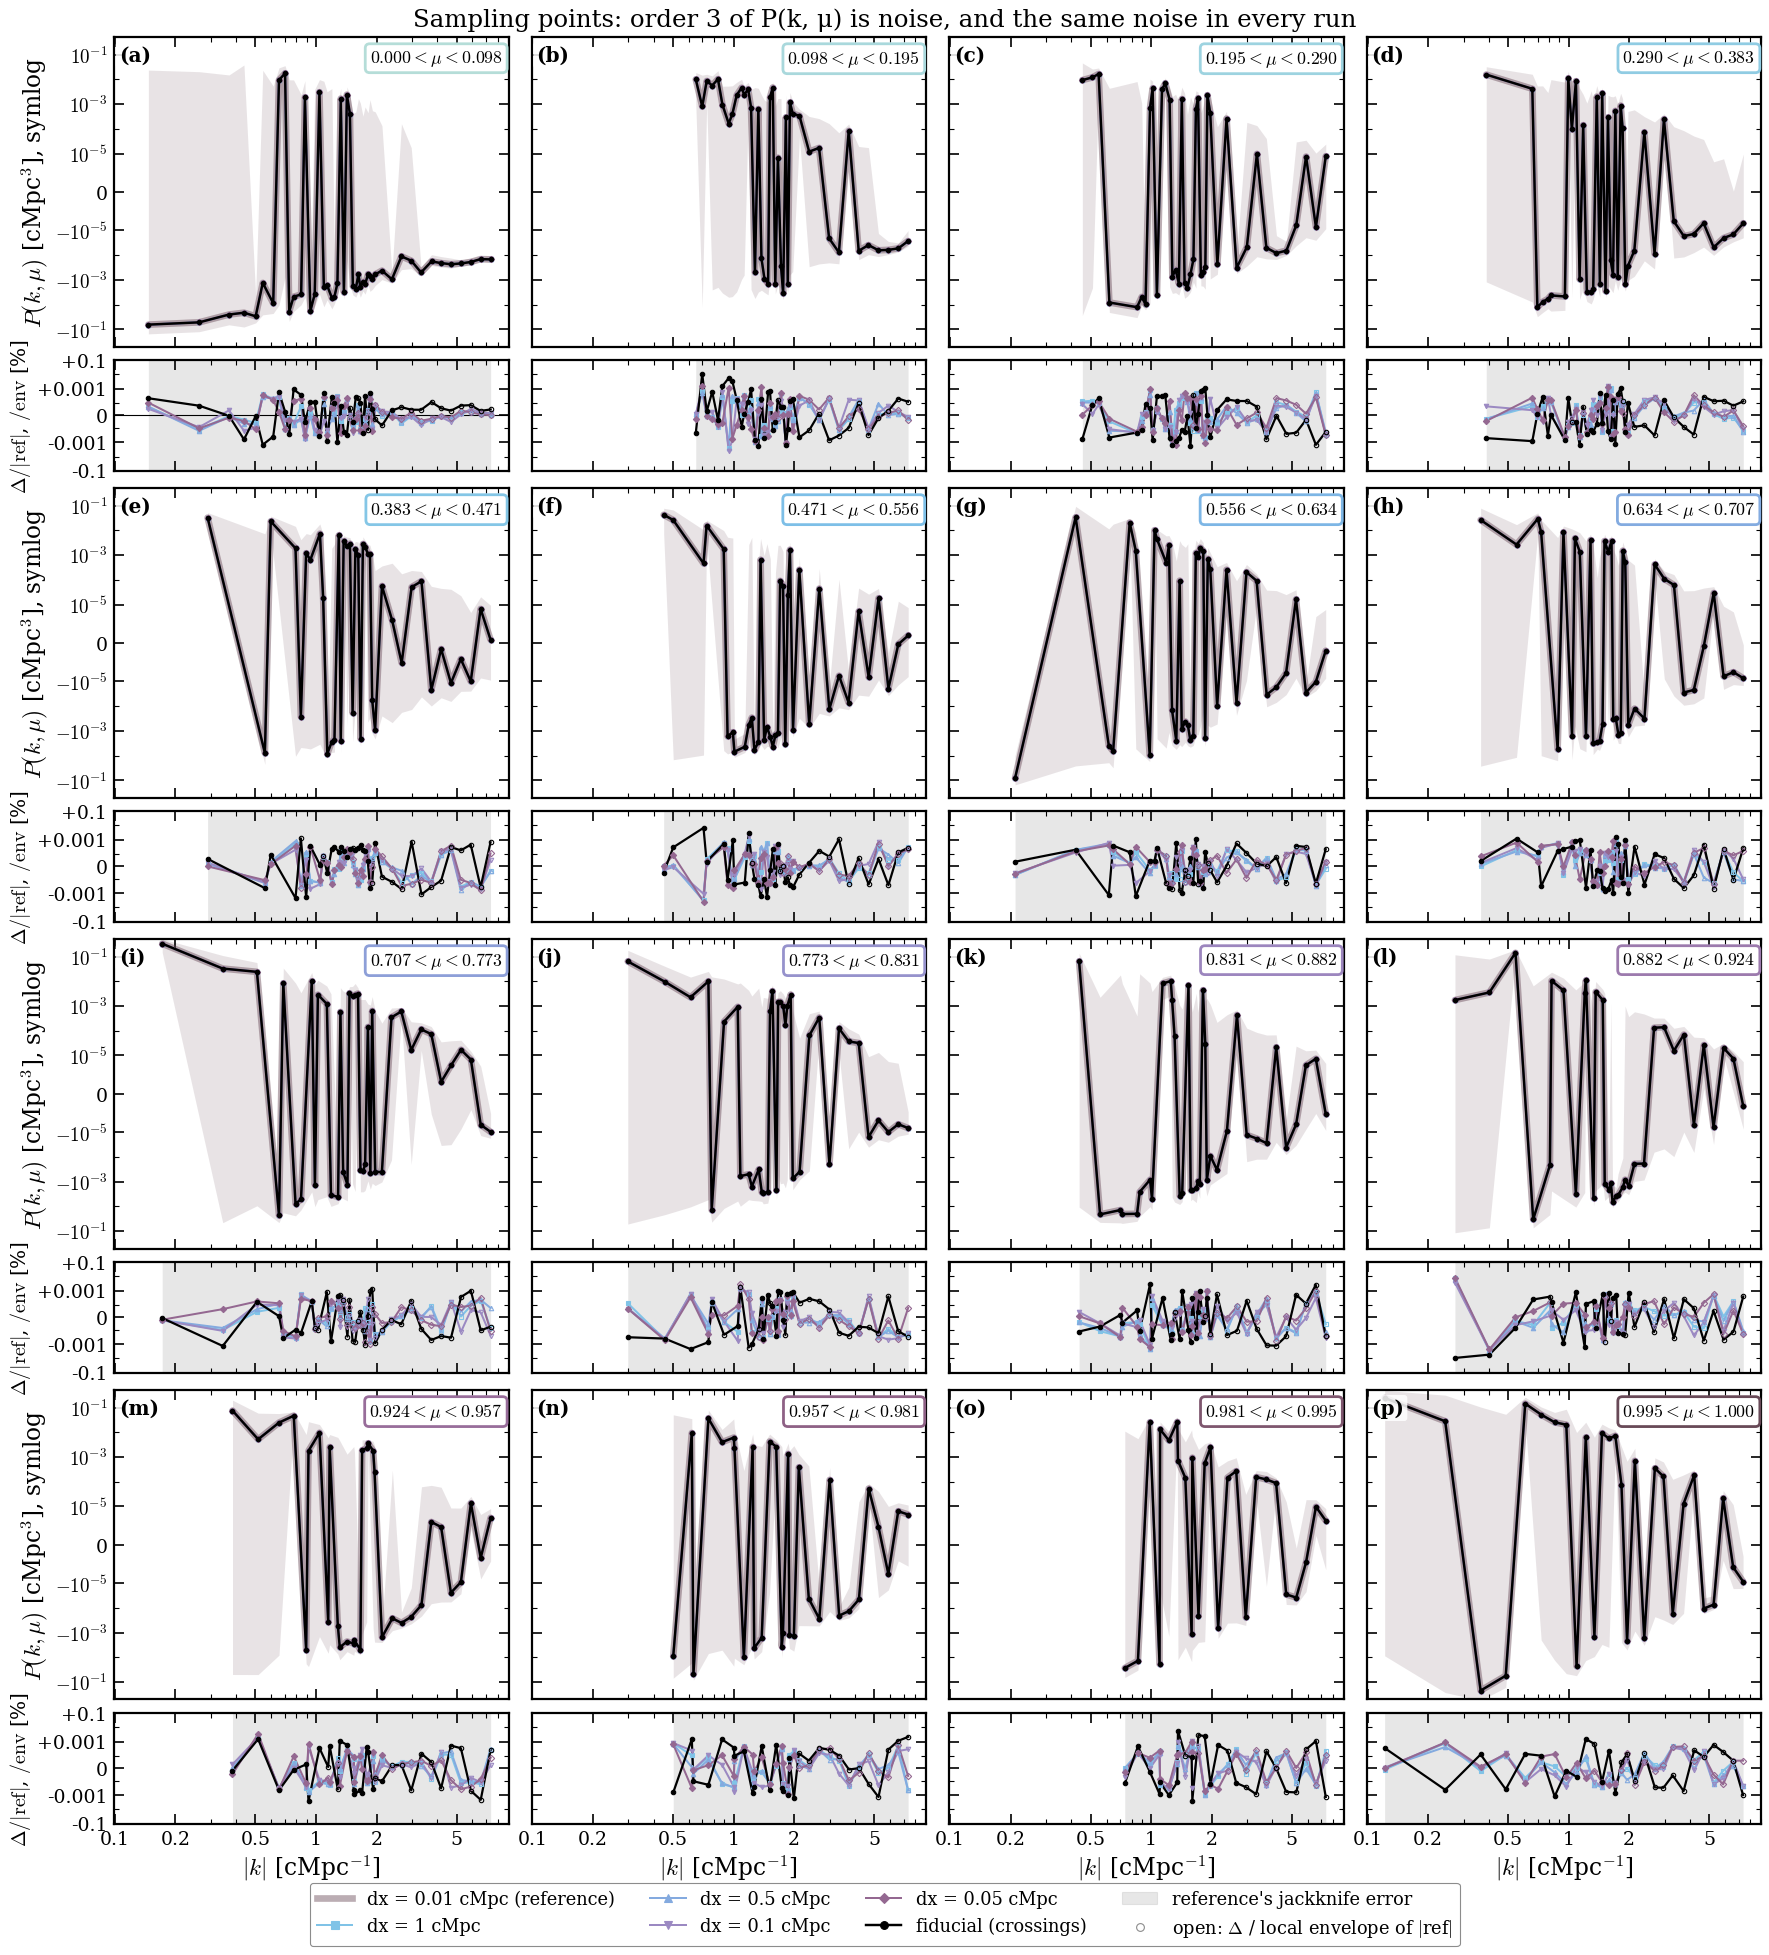

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dx_1cMpc       order 3                            9.21e-05       0.0073         110       0%
dx_0p5cMpc     order 3                            8.83e-05      0.00545         110       0%
dx_0p1cMpc     order 3                            8.57e-05      0.00426         110       0%
dx_0p05cMpc    order 3                            8.91e-05      0.00801         110       0%
reference      order 3                            0.000223       0.0108         110       0%


In [9]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('order 3',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'order 3': "Sampling points: order 3 of P(k, μ) is noise, and the same noise in every run"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('order 3',), "P_mu"))

*Reading (order 3).* Order 3 changes sign from bin to bin and its jackknife error exceeds its envelope (110%):
it is noise. The runs nevertheless share it to $\sim 10^{-4}$% of the envelope: the same skewers, the same noise.

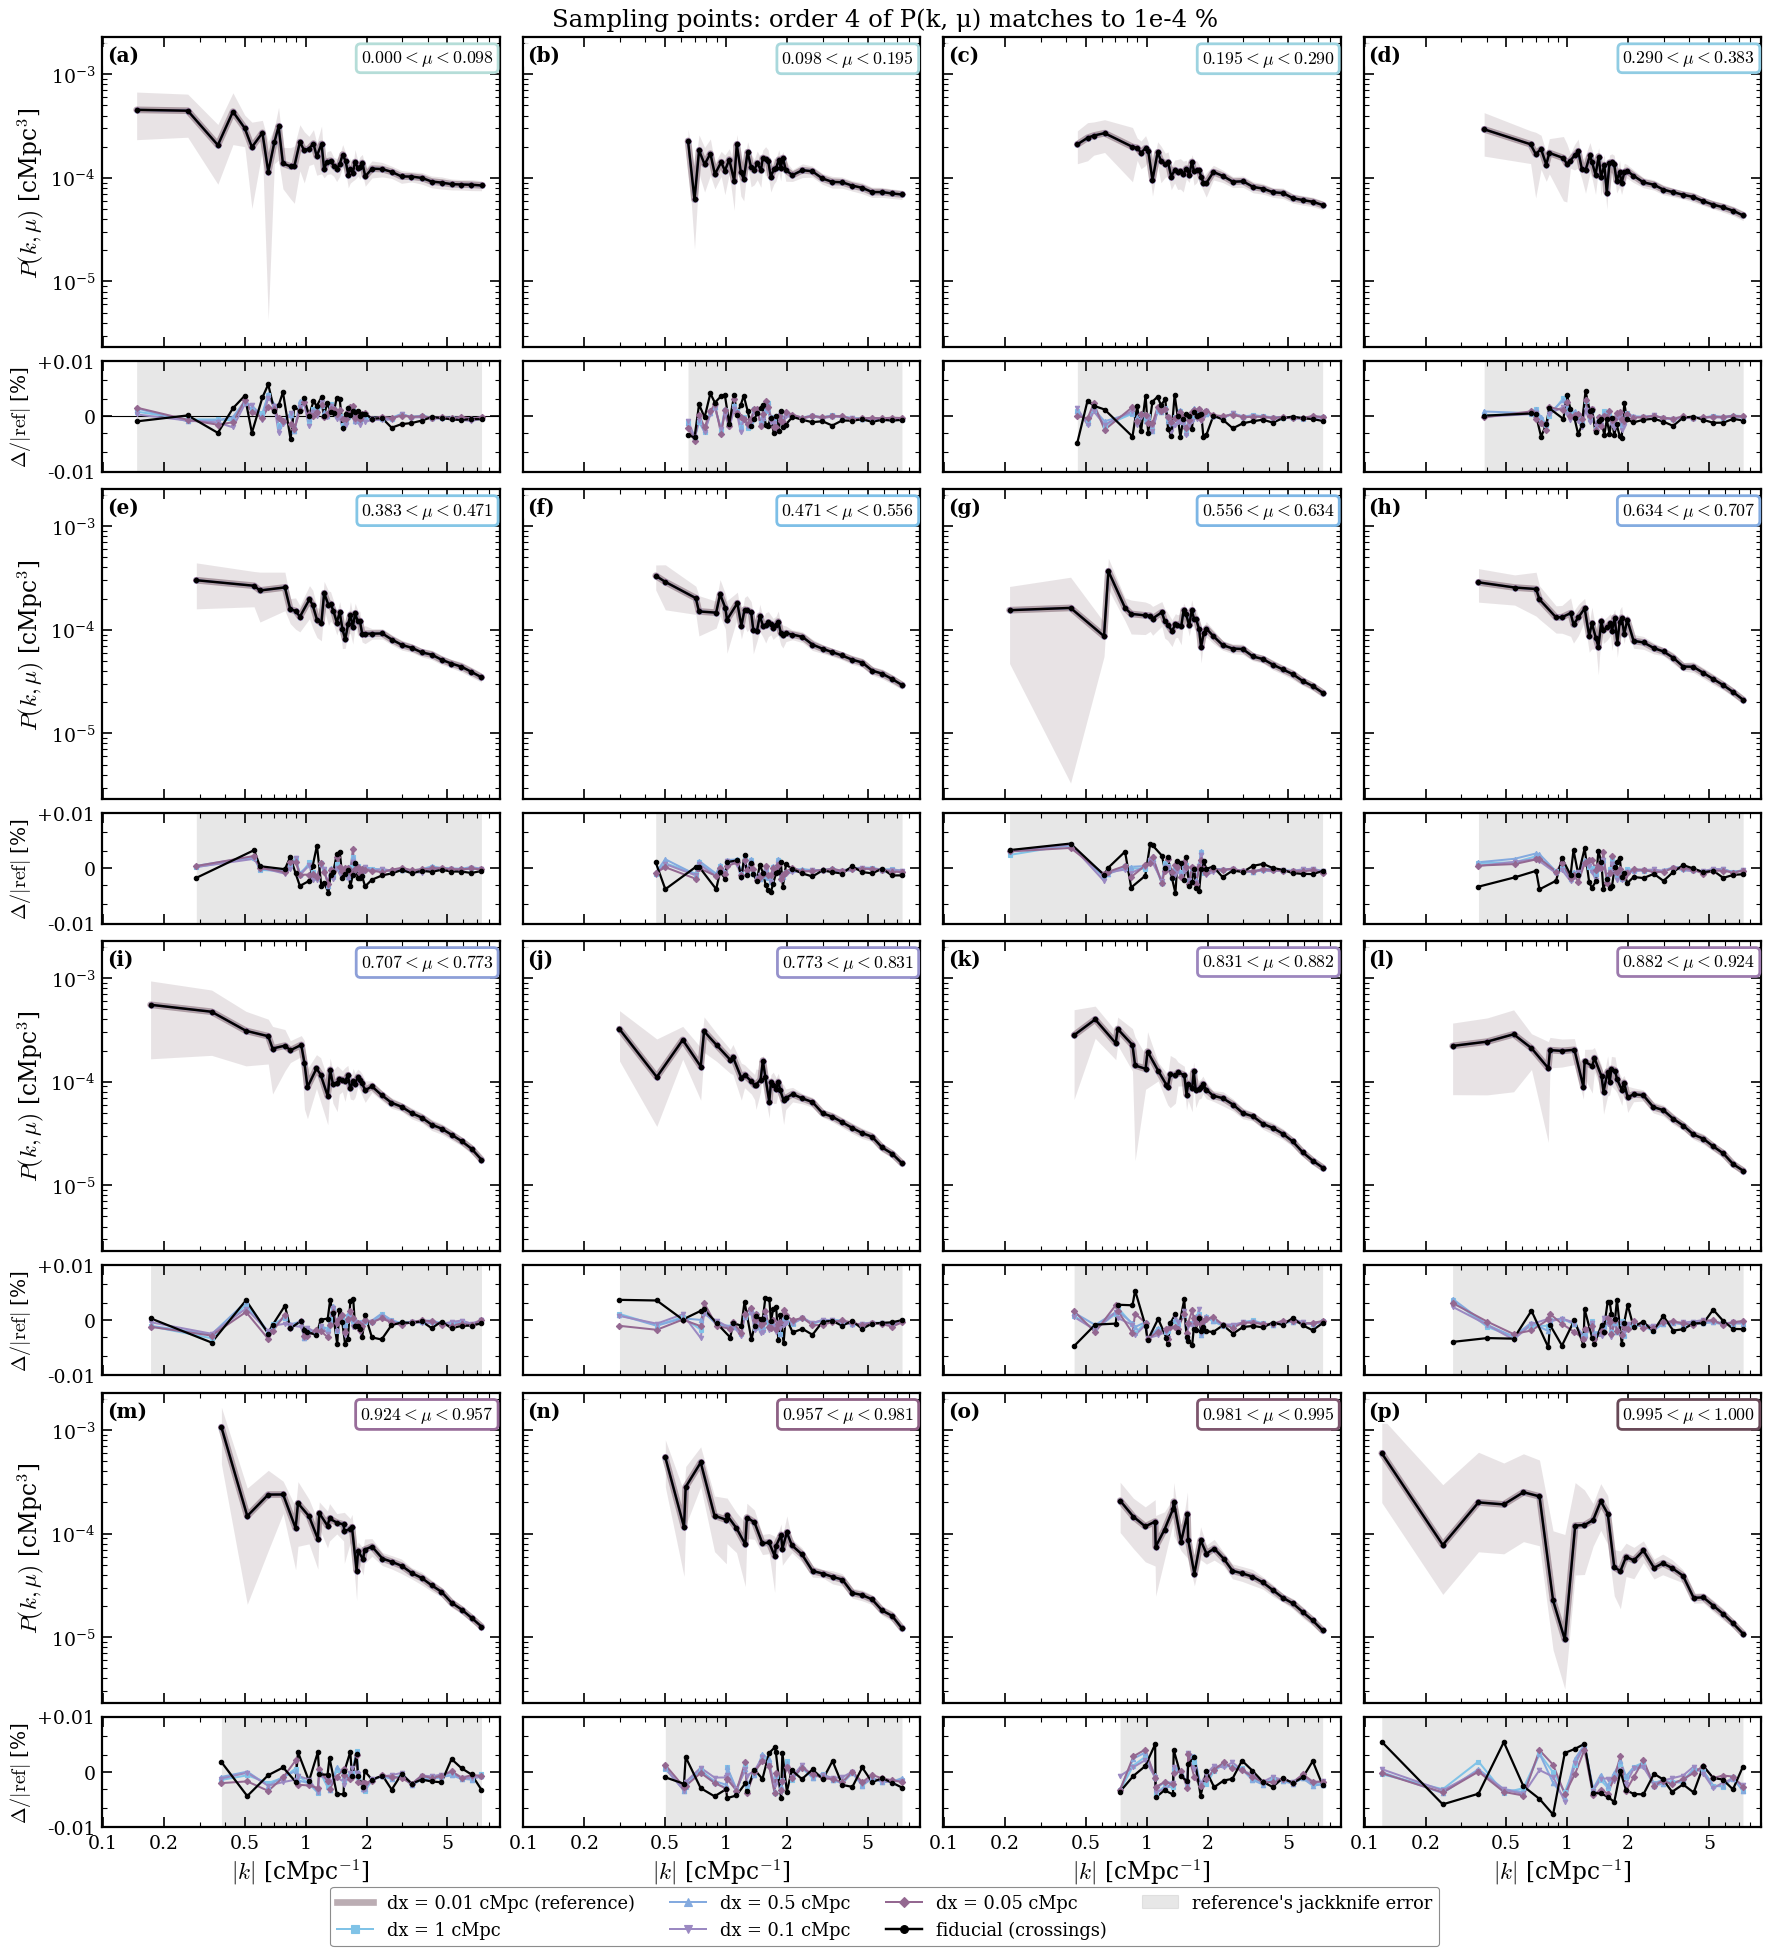

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dx_1cMpc       order 4                            2.48e-05     0.000348          25       0%
dx_0p5cMpc     order 4                            2.51e-05     0.000345          25       0%
dx_0p1cMpc     order 4                            2.48e-05     0.000452          25       0%
dx_0p05cMpc    order 4                            2.65e-05     0.000245          25       0%
reference      order 4                            4.89e-05      0.00214          25       0%


In [10]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('order 4',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'order 4': "Sampling points: order 4 of P(k, μ) matches to 1e-4 %"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('order 4',), "P_mu"))

*Reading (order 4).* Order 4, the product of the two overfluxes with itself, agrees to a median $3\times10^{-5}$%
(at most $2\times10^{-3}$%), against a 25% error.

### E2 · The wedges term by term (order 2)

One figure each for the $\mathrm{Ly}\alpha$ auto, the Si III auto and the cross term.

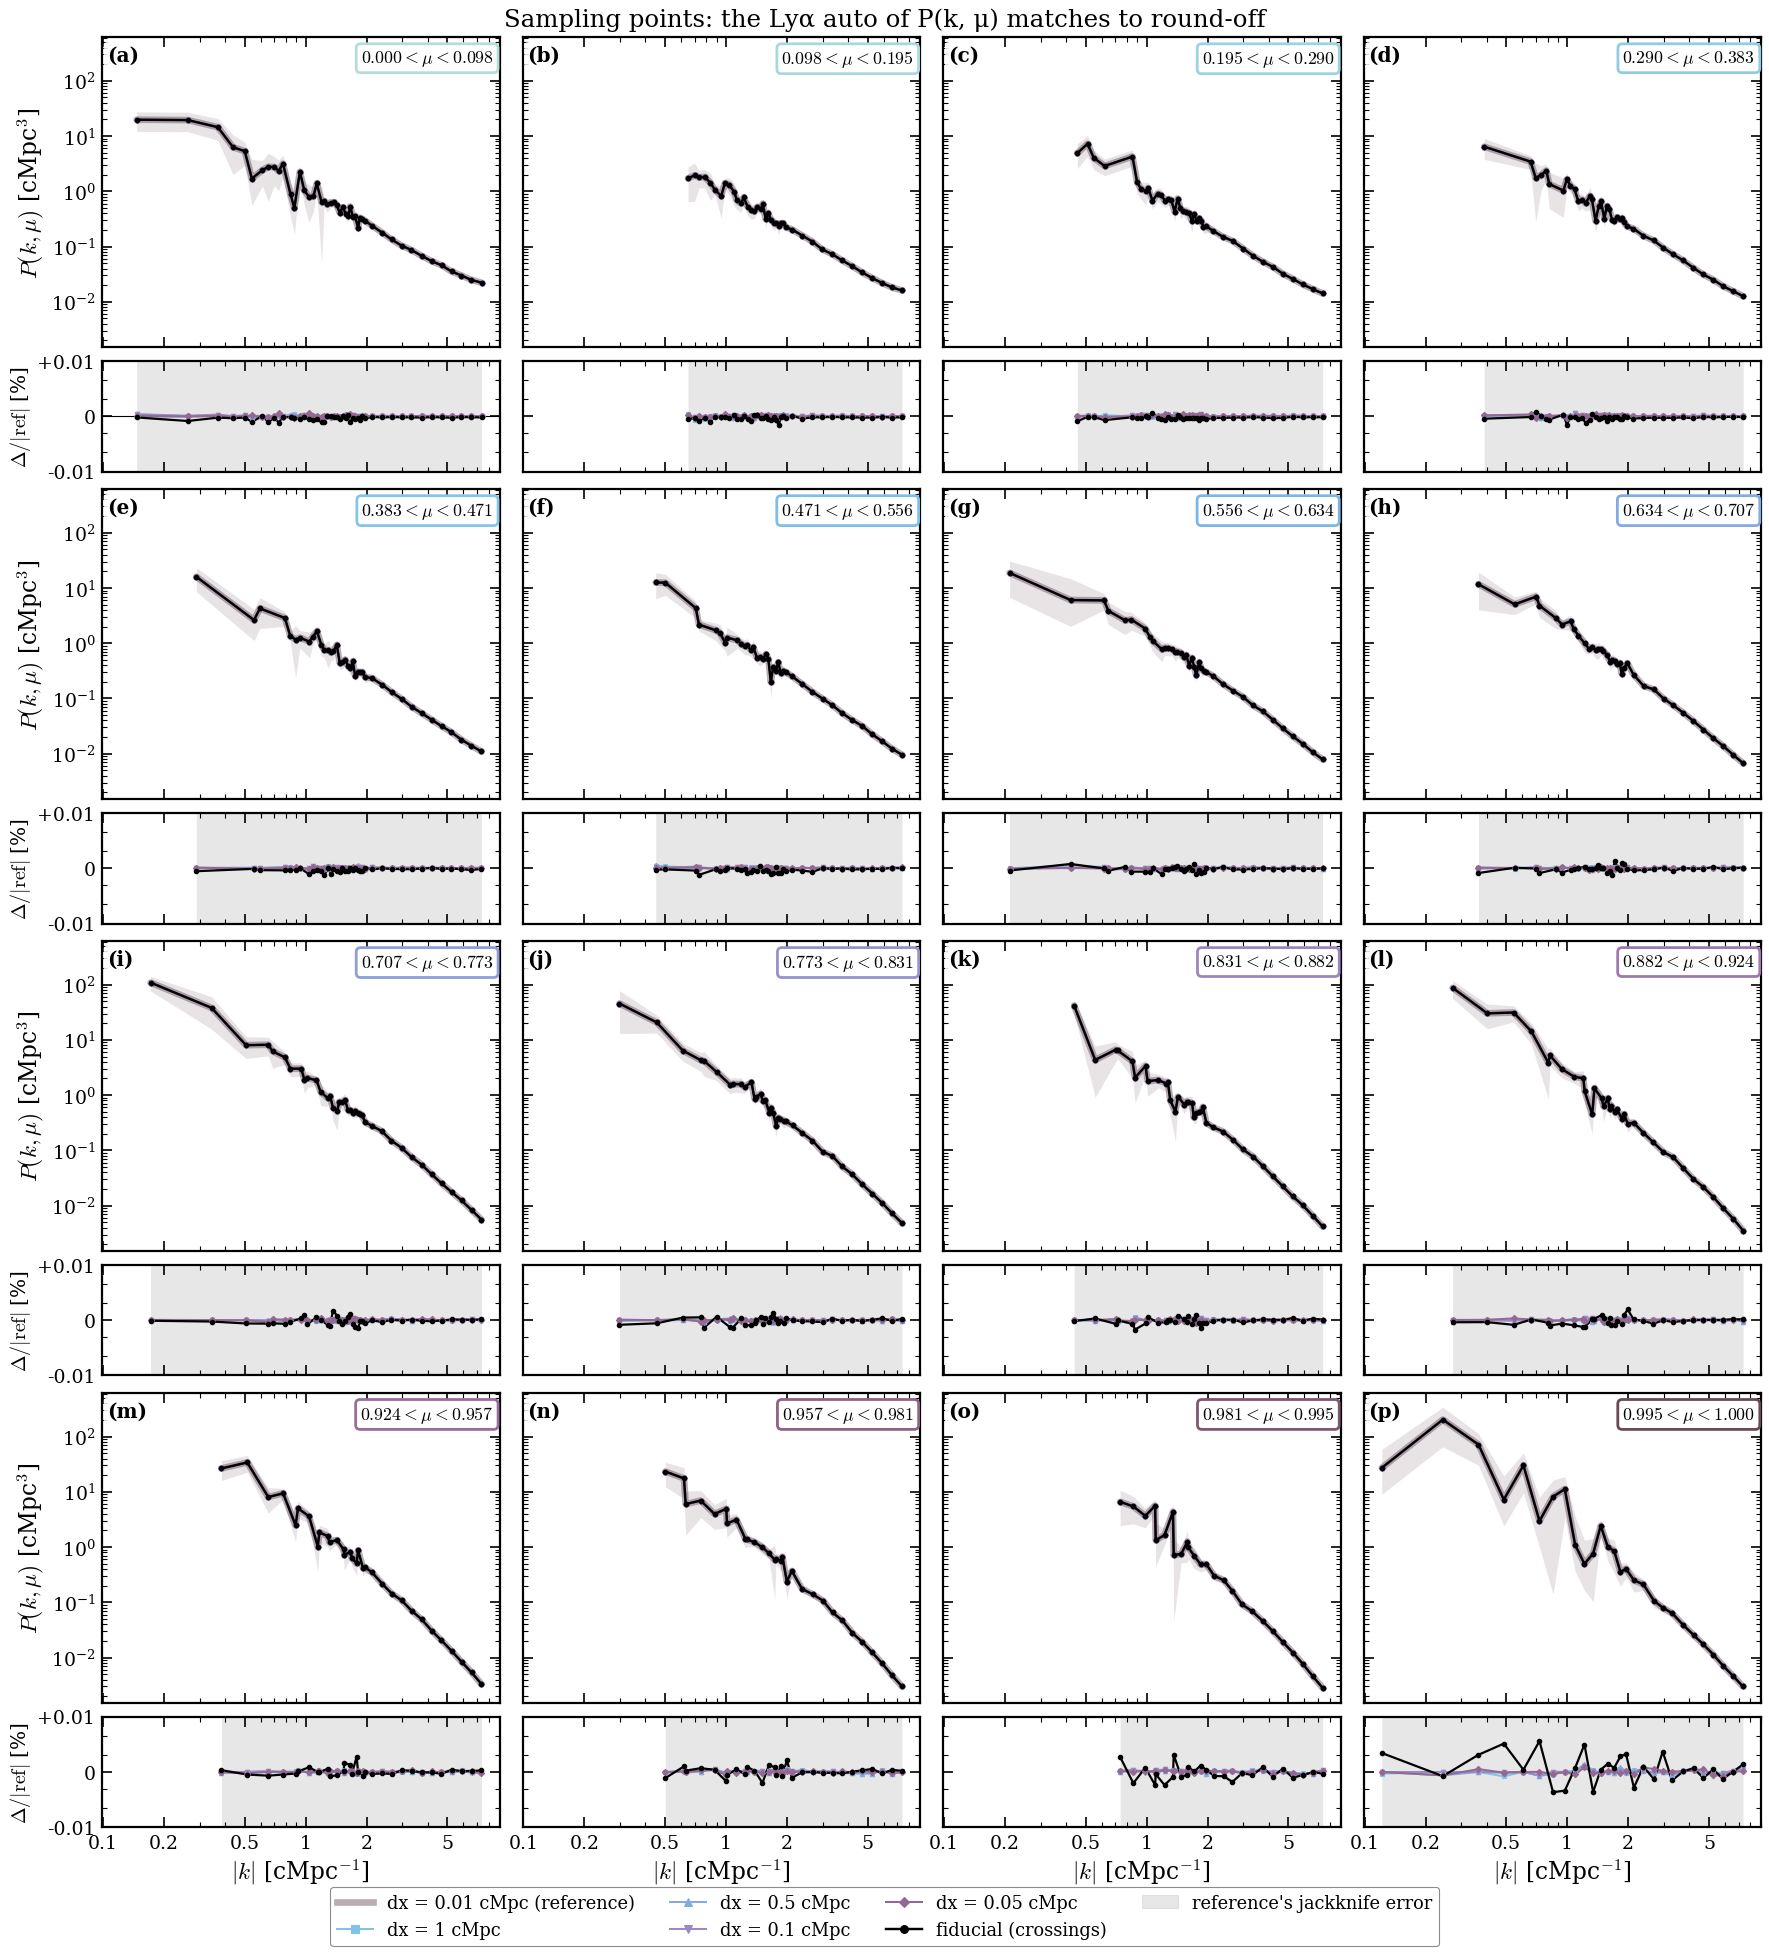

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dx_1cMpc       HI-LyA|HI-LyA                      2.99e-06     3.58e-05          22       0%
dx_0p5cMpc     HI-LyA|HI-LyA                      2.91e-06     4.49e-05          22       0%
dx_0p1cMpc     HI-LyA|HI-LyA                      2.73e-06      3.6e-05          22       0%
dx_0p05cMpc    HI-LyA|HI-LyA                      2.68e-06     2.69e-05          22       0%
reference      HI-LyA|HI-LyA                      1.03e-05     0.000531          22       0%


In [11]:
fig, main, res = plot_runs_pk_mu_terms(CMP_T, STYLES, TERMS_REF, terms=(TERMS[0],), line_ids=LINE_IDS, labels=RUN_LABELS,
                                       linthresh=RES_LINTHRESH, titles={TERMS[0]: "Sampling points: the Lyα auto of P(k, μ) matches to round-off"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, (TERMS[0],), "P_mu"))

*Reading (term 1).* Median $3\times10^{-6}$%, as the total, in every wedge.

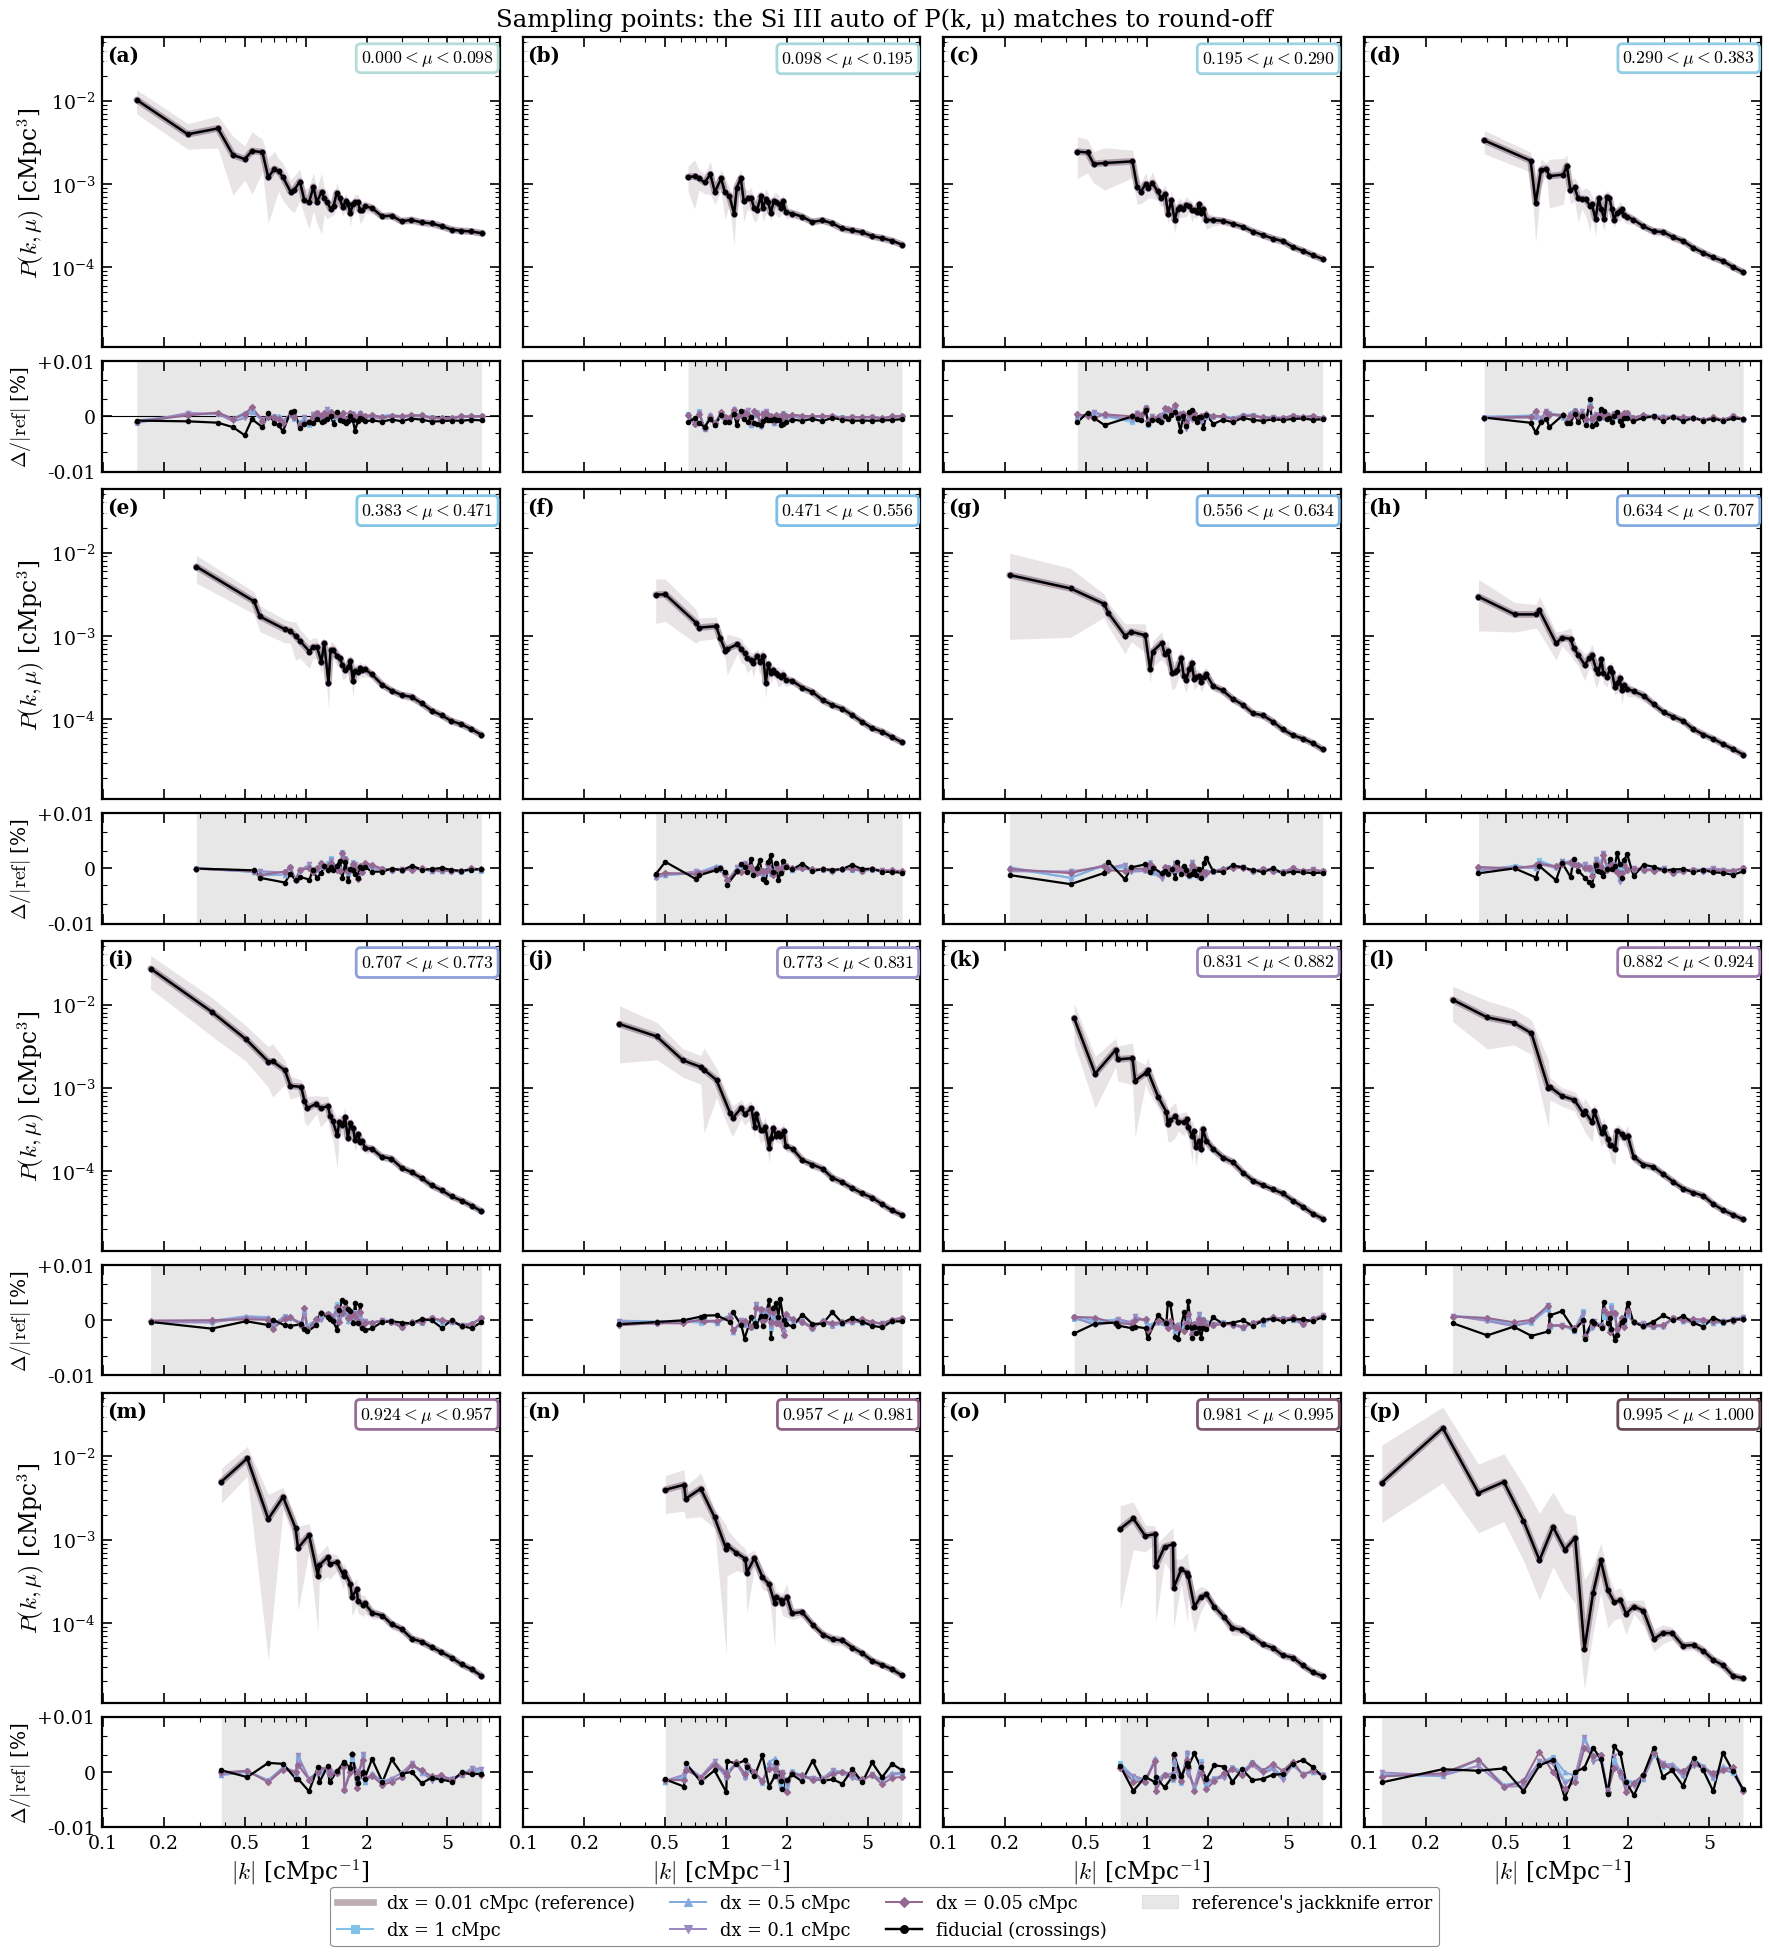

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dx_1cMpc       SiIII-1206|SiIII-1206              1.65e-05     0.000664        23.5       0%
dx_0p5cMpc     SiIII-1206|SiIII-1206              1.61e-05     0.000722        23.5       0%
dx_0p1cMpc     SiIII-1206|SiIII-1206              1.61e-05     0.000903        23.5       0%
dx_0p05cMpc    SiIII-1206|SiIII-1206              1.49e-05     0.000226        23.5       0%
reference      SiIII-1206|SiIII-1206              2.81e-05     0.000287        23.5       0%


In [12]:
fig, main, res = plot_runs_pk_mu_terms(CMP_T, STYLES, TERMS_REF, terms=(TERMS[1],), line_ids=LINE_IDS, labels=RUN_LABELS,
                                       linthresh=RES_LINTHRESH, titles={TERMS[1]: "Sampling points: the Si III auto of P(k, μ) matches to round-off"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, (TERMS[1],), "P_mu"))

*Reading (term 2).* Median $2\times10^{-5}$% (at most $10^{-3}$%): Si III, the narrowest line, is as insensitive to
where the pieces are cut as $\mathrm{Ly}\alpha$, because the integrated profile integrates each crossing exactly.

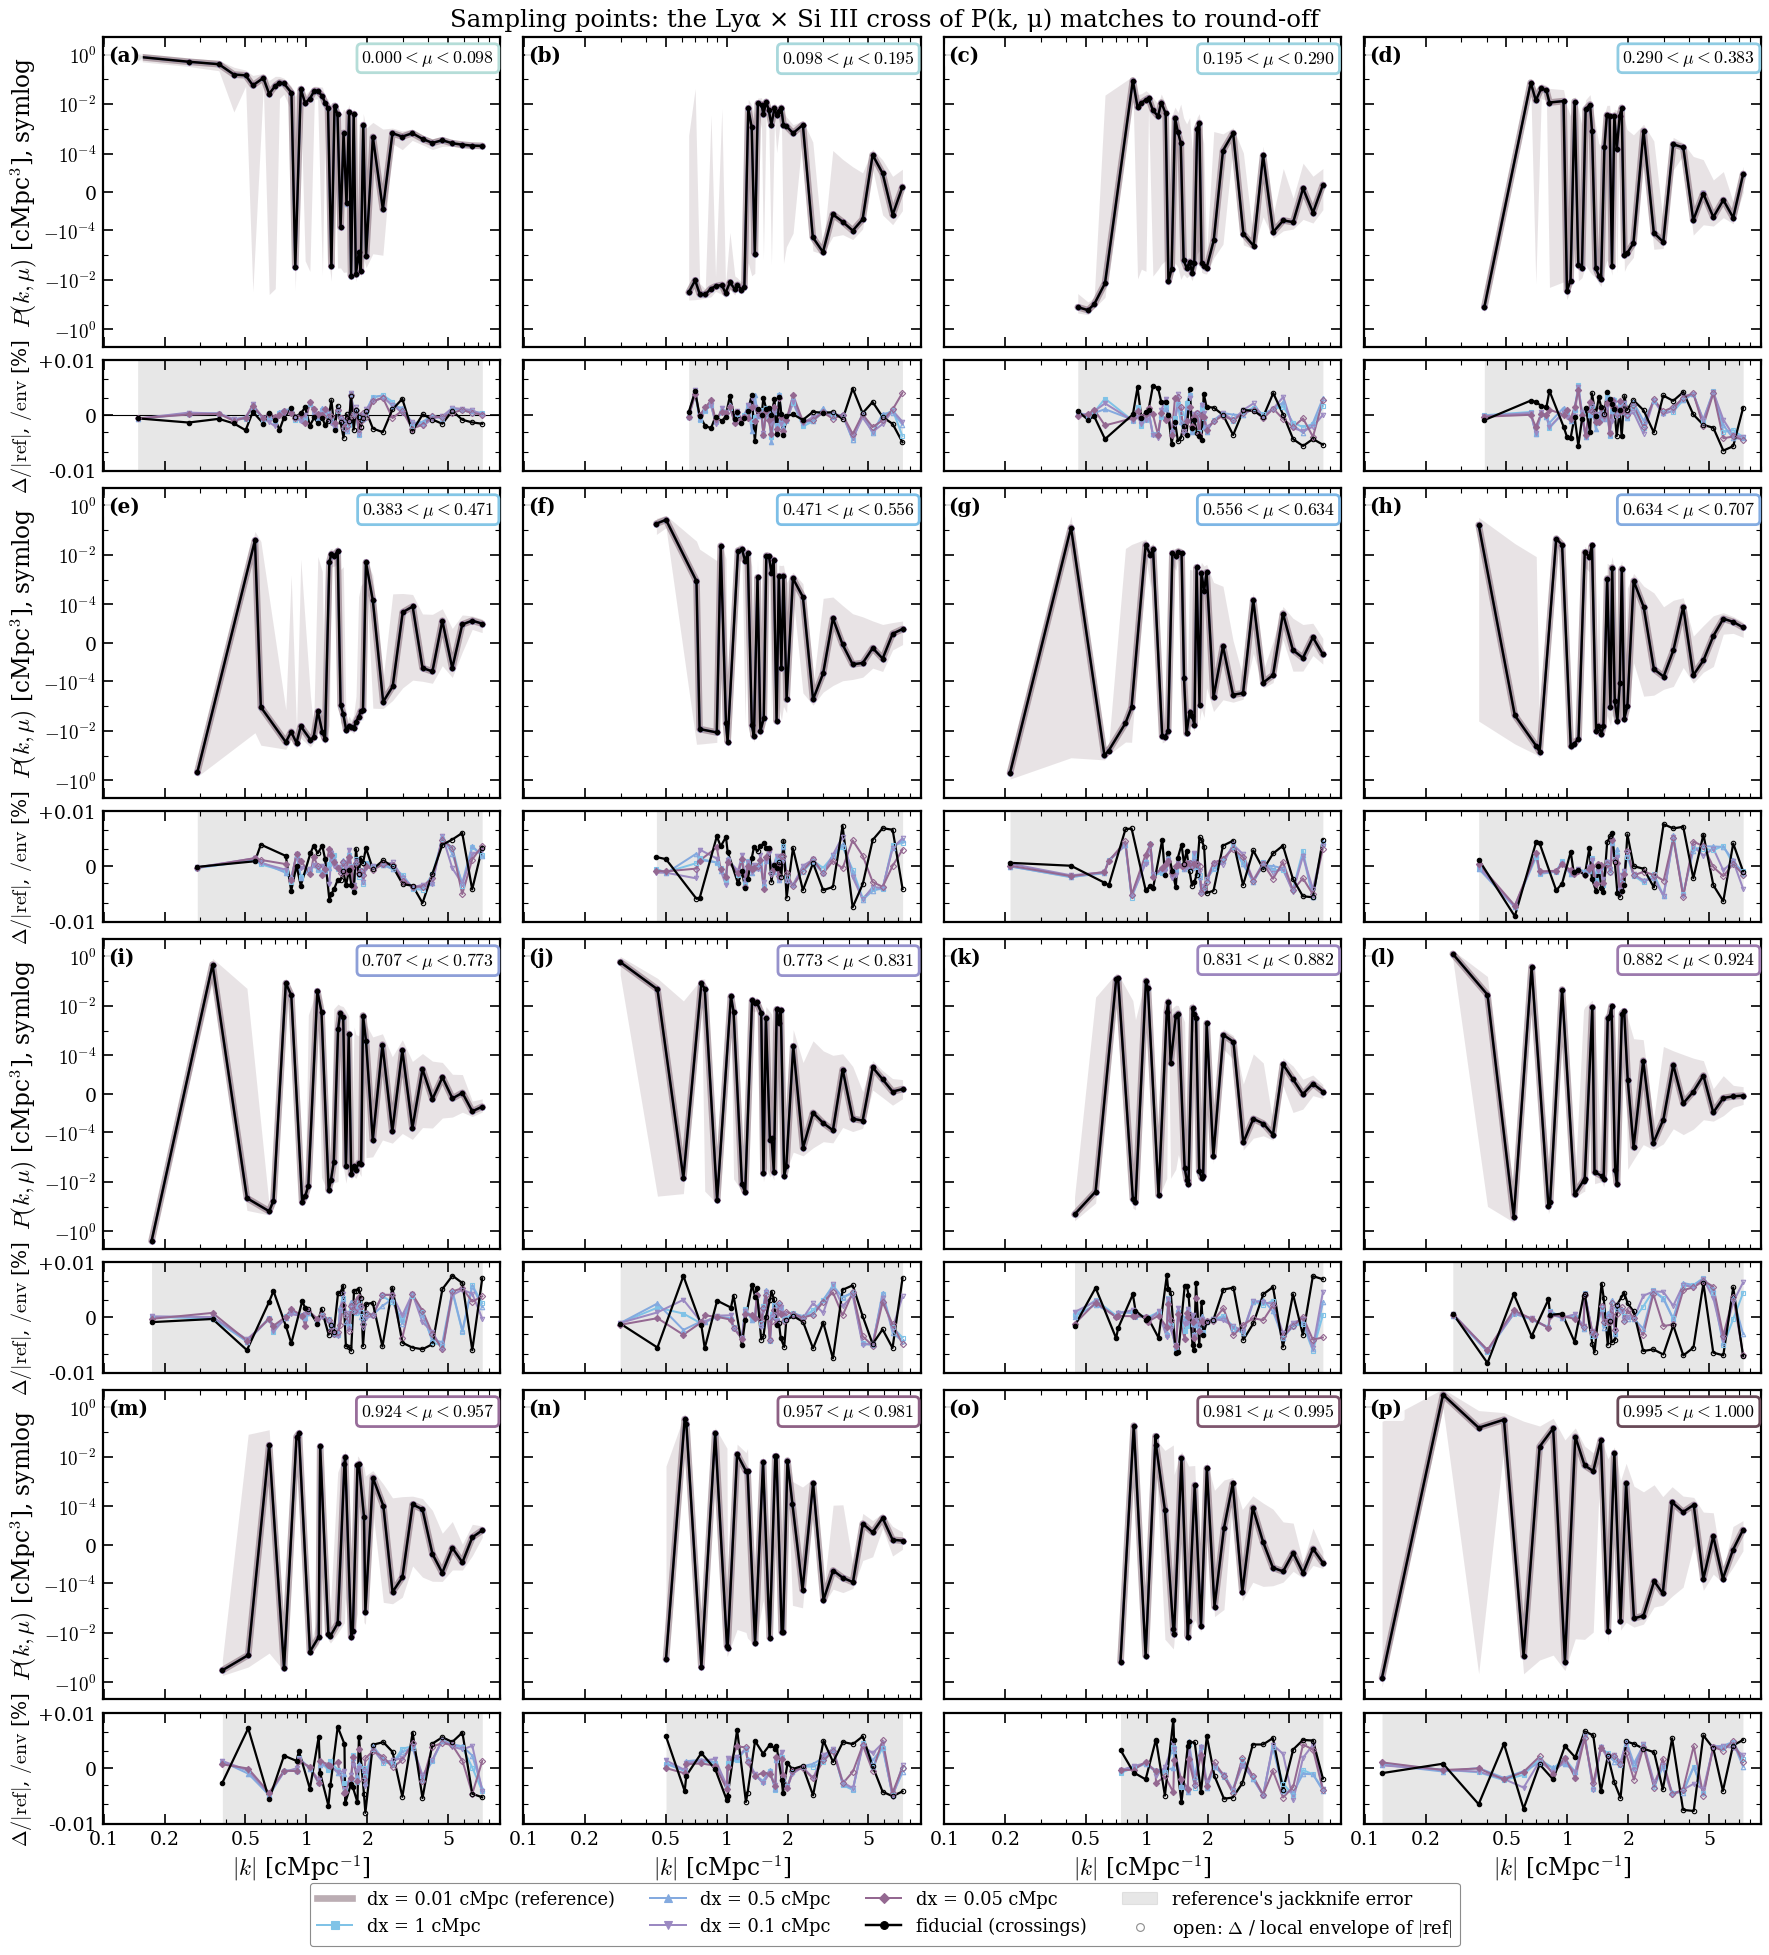

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dx_1cMpc       HI-LyA|SiIII-1206                  4.25e-05      0.00151        67.3       0%
dx_0p5cMpc     HI-LyA|SiIII-1206                  4.27e-05      0.00179        67.3       0%
dx_0p1cMpc     HI-LyA|SiIII-1206                   4.4e-05      0.00159        67.3       0%
dx_0p05cMpc    HI-LyA|SiIII-1206                  4.36e-05      0.00144        67.3       0%
reference      HI-LyA|SiIII-1206                  0.000128      0.00521        67.3       0%


In [13]:
fig, main, res = plot_runs_pk_mu_terms(CMP_T, STYLES, TERMS_REF, terms=(TERMS[2],), line_ids=LINE_IDS, labels=RUN_LABELS,
                                       linthresh=RES_LINTHRESH, titles={TERMS[2]: "Sampling points: the Lyα × Si III cross of P(k, μ) matches to round-off"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, (TERMS[2],), "P_mu"))

*Reading (term 3).* The cross oscillates as $\cos(k\mu\Delta)$ and changes sign; relative to its local envelope the
runs agree to $4\times10^{-5}$% (median), against a 67% error.

## Part F — The converged range

For every run and statistic, the largest $k$ up to which **every** bin differs from the reference by less than 0.1%,
0.5% and 1% (`k_max_table`: P1D on its native modes, $P(k, \mu)$ on its $|k|$ bins; "$\geq k$" when every bin passes up to
the run's last one; 0 when the first bin already fails). The last columns give the run's last bin and the median
jackknife error of the relative difference: a $k_{\max}$ set by bins whose difference is within that error is limited
by noise, not by the parameter. The figure draws $k_{\max}(0.5\%)$ against the spacing $dx$.


The table is given twice: against the fiducial (the exact crossings) and against the finest spacing.

against reference; P1D on its native modes [s/km], P(k, mu) on its |k| bins [1/cMpc]; '>= k': every bin passes up to the run's last one; the DESI DR1 P1D reaches k = 0.032 s/km at z = 3.0
run            statistic                         k_max(0.1%)    k_max(0.5%)      k_max(1%)  last bin jk err [%]  unit
dx_1cMpc       P1D HI-LyA                               1.36           1.58           1.58      3.14         17  s/km
dx_1cMpc       P1D SiIII-1206                        >= 3.14        >= 3.14        >= 3.14      3.14     0.0013  s/km
dx_1cMpc       P1D total                                2.89        >= 3.14        >= 3.14      3.14     0.0016  s/km
dx_1cMpc       P(k, mu) total mu 0.00-0.50           >= 7.38        >= 7.38        >= 7.38      7.38    8.8e-06  1/cMpc
dx_1cMpc       P(k, mu) total mu 0.50-0.80           >= 7.38        >= 7.38        >= 7.38      7.38    1.4e-05  1/cMpc
dx_1cMpc       P(k, mu) total mu 0.80-0.95           >= 7.38        >= 7.38        >= 7.38      7.38

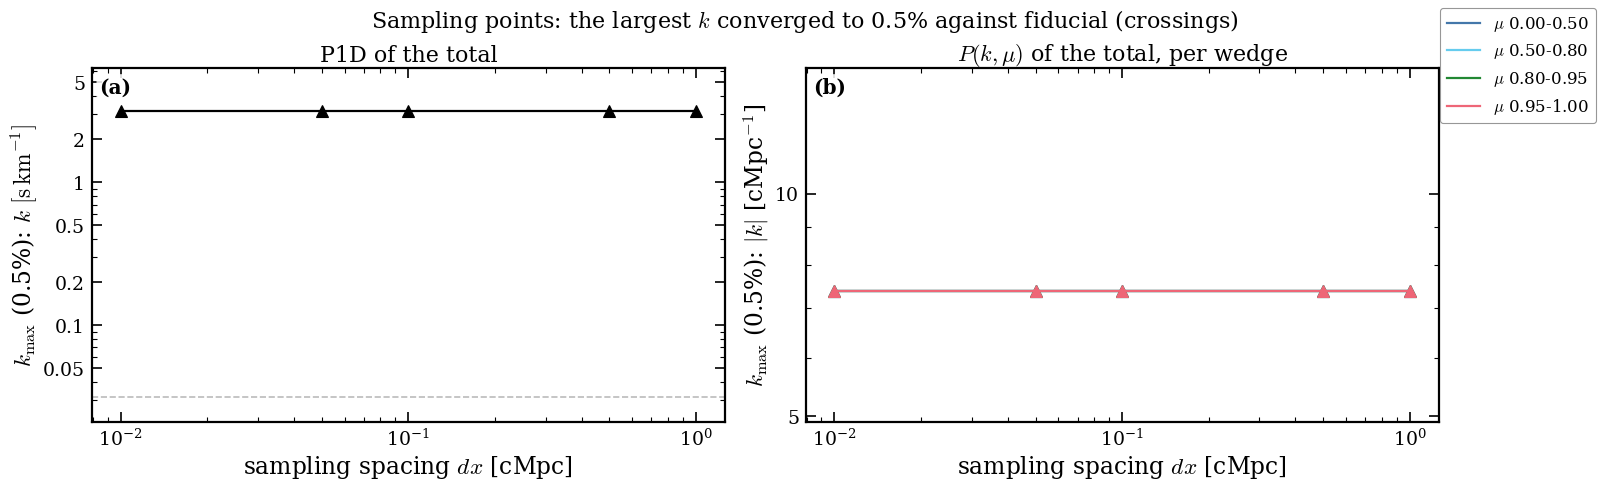


against the finest spacing dx_0p01cMpc:
run            statistic                         k_max(0.1%)    k_max(0.5%)      k_max(1%)  last bin jk err [%]  unit
dx_1cMpc       P1D HI-LyA                               1.47           1.58           1.59      3.14         15  s/km
dx_1cMpc       P1D SiIII-1206                        >= 3.14        >= 3.14        >= 3.14      3.14     0.0014  s/km
dx_1cMpc       P1D total                             >= 3.14        >= 3.14        >= 3.14      3.14     0.0018  s/km
dx_1cMpc       P(k, mu) total mu 0.00-0.50           >= 7.38        >= 7.38        >= 7.38      7.38    5.9e-06  1/cMpc
dx_1cMpc       P(k, mu) total mu 0.50-0.80           >= 7.38        >= 7.38        >= 7.38      7.38    7.1e-06  1/cMpc
dx_1cMpc       P(k, mu) total mu 0.80-0.95           >= 7.38        >= 7.38        >= 7.38      7.38      9e-06  1/cMpc
dx_1cMpc       P(k, mu) total mu 0.95-1.00           >= 7.38        >= 7.38        >= 7.38      7.38    1.6e-05  1/cMpc
dx_0p5c

In [14]:
ROWS = k_max_table(CMP_ALL, TOLS)
print(f"against {REFERENCE}; P1D on its native modes [s/km], P(k, mu) on its |k| bins [1/cMpc]; '>= k': every bin passes "
      f"up to the run's last one; the DESI DR1 P1D reaches k = {K_DESI:.3f} s/km at z = {P1D_REF['z']}")
print(format_k_max_table(ROWS, TOLS))
fig, axs = plot_k_max_summary(ROWS, X_OF_RUN, xlabel=X_LABEL, xscale=X_SCALE, xticks=X_TICKS, tol=0.005, p1d_k_ref=K_DESI,
                              title=f"{TITLE_STEM}: the largest $k$ converged to 0.5% against {RUN_LABELS[REFERENCE]}")
add_panel_letters(axs)
plt.show()

print(f"\nagainst the finest spacing {FINEST}:")
print(format_k_max_table(k_max_table(CMP_FINEST_ALL, TOLS), TOLS))

**Reading.** With the integrated profile the sampling spacing does not matter. Against the fiducial (the exact crossings),
every spacing from 1 to 0.01 cMpc gives:

* the mean transmission to $3\times10^{-8}$;
* $P(k, \mu)$ of the total to better than 0.1% in every wedge, up to the last bin (7.4 cMpc$^{-1}$);
* $P_\mathrm{1D}$ of Si III and of the total to 0.5% up to the Nyquist frequency (3.1 s/km).

Only $P_\mathrm{1D}$ of $\mathrm{Ly}\alpha$ departs, beyond $k \approx 1.4$–1.6 s/km, 50 times beyond the DESI DR1 range
(0.032 s/km). There it is $10^{-10}$ of its peak and its jackknife error is 10–20%: the float32 round-off of saturated
absorbers ($|\Delta\tau|$ up to $\sim 10^3$ where $\tau \sim 10^8$). The same holds against the finest spacing.

In the sampled route a coarse spacing costs more, not less, because the reach of the dual segments widens: $dx$ = 1 cMpc
took $\sim$5 h for $128^2$ skewers, 0.05 cMpc took 32 min. The crossings route of the fiducial needs no sampling points
(2.5 min).